# K-means Algorithm for Quality Management and Prediction of Gastronomic Preferences
## Notebook de Correcciones — Respuesta a Revisores (IJIES Paper ID: 20261382)

Este notebook aborda **sistemáticamente cada crítica** del reviewer:

| Crítica | Sección | Estado |
|---------|---------|--------|
| #1 Abstract sin datos | §0 — Resumen final | ✅ |
| #7 Dataset muy pequeño | §1 — Carga y exploración | ✅ 445,474 registros |
| #8 Integración de fuentes | §2 — Trazabilidad por fuente | ✅ |
| #10 Leakage sentimiento≈rating (r=0.99) | §3 — NLP independiente en español | ✅ |
| #3 #6 Sin respaldo estadístico | §4 — EDA + ANOVA | ✅ |
| #9 Clustering ≠ predicción | §5 — Clasificador supervisado | ✅ |
| #11 Validación débil | §6 — Validación robusta | ✅ |
| #5 Figuras borrosas | §7 — Figuras de alta calidad (300 DPI) | ✅ |
| #12 Conclusión sin teoría | §8 — Métricas y discusión | ✅ |

---
## §0 — Instalación de Dependencias

In [30]:
# Instalar librerías necesarias (ejecutar una sola vez)
# pip install pysentimiento langdetect scikit-learn pandas numpy matplotlib seaborn scipy tqdm

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats import f_oneway, kruskal
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.utils import resample
from tqdm import tqdm

# Configuración global de figuras (300 DPI para publicación)
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'font.family': 'DejaVu Sans'
})

RANDOM_STATE = 42
print("✅ Dependencias cargadas correctamente")

✅ Dependencias cargadas correctamente


---
## §1 — Carga y Exploración del Dataset
**Crítica #7:** El dataset efectivo tenía solo ~25 registros. Este dataset tiene 445,474 registros.

In [31]:
# ─────────────────────────────────────────────
# AJUSTA ESTA RUTA A TU ARCHIVO
# ─────────────────────────────────────────────
DATASET_PATH = "./reviews.csv"

# Carga con tipos explícitos para optimizar memoria
dtype_map = {
    'id_review': str,
    'review':    str,
    'title':     str,
    'score':     float,
    'likes':     float,
    'id_nick':   str,
    'service':   str,
    'date':      str,
    'platform':  str
}

df_raw = pd.read_csv(
    DATASET_PATH,
    dtype=dtype_map,
    low_memory=False,
    encoding='utf-8',
    on_bad_lines='skip'
)

print(f"{'='*55}")
print(f" DATASET CARGADO")
print(f"{'='*55}")
print(f" Filas totales        : {len(df_raw):>10,}")
print(f" Columnas             : {df_raw.shape[1]:>10}")
print(f" Memoria (MB)         : {df_raw.memory_usage(deep=True).sum()/1e6:>10.1f}")
print(f"{'='*55}")
df_raw.head(3)

 DATASET CARGADO
 Filas totales        :  1,258,435
 Columnas             :          9
 Memoria (MB)         :      596.6


,id_review,review,title,score,likes,id_nick,service,date,platform
0,R1245,Muy buena presentación y servicio sin embargo ...,Muy buena presentación y servicio,3.0,0.0,uisahelenad2018,71036.0,1 years ago,tripadvisor
1,R1246,Desde la presentación de los platos a la calid...,Una experiencia,5.0,0.0,turrutia,71036.0,1 years ago,tripadvisor
2,R1247,El mejor lugar para reencontrame con mis amigo...,Felicitaciones a Statera!,5.0,0.0,orthStar25333985745,71036.0,1 years ago,tripadvisor


In [32]:
# ──────────────────────────────────────────
# Informe de integridad (Crítica #3 — datos)
# ──────────────────────────────────────────
print("\n📊 INFORME DE INTEGRIDAD")
print("-" * 45)
missing = df_raw.isnull().sum()
pct_missing = (missing / len(df_raw) * 100).round(2)
integrity = pd.DataFrame({
    'Nulos': missing,
    '% Nulo': pct_missing,
    'Dtype': df_raw.dtypes
})
print(integrity)

print(f"\n Duplicados exactos   : {df_raw.duplicated().sum():,}")
print(f" IDs únicos           : {df_raw['id_review'].nunique():,}")


📊 INFORME DE INTEGRIDAD
---------------------------------------------
            Nulos  % Nulo    Dtype
id_review       0     0.0   object
review     503369    40.0   object
title           0     0.0   object
score           0     0.0  float64
likes           0     0.0  float64
id_nick         0     0.0   object
service         0     0.0   object
date            0     0.0   object
platform        0     0.0   object

 Duplicados exactos   : 0
 IDs únicos           : 1,258,435


In [33]:
# ──────────────────────────────────────────
# Estadísticas descriptivas (Crítica #6)
# ──────────────────────────────────────────
print("\n📈 ESTADÍSTICAS DESCRIPTIVAS — score y likes")
print(df_raw[['score', 'likes']].describe().round(3))

# Distribución de plataformas
print("\n🌐 DISTRIBUCIÓN POR PLATAFORMA (Crítica #8)")
platform_dist = df_raw['platform'].value_counts()
print(platform_dist.to_frame('registros'))


📈 ESTADÍSTICAS DESCRIPTIVAS — score y likes
             score        likes
count  1258435.000  1258435.000
mean         4.162        0.050
std          1.092        0.272
min          1.000        0.000
25%          4.000        0.000
50%          5.000        0.000
75%          5.000        0.000
max          5.000       31.000

🌐 DISTRIBUCIÓN POR PLATAFORMA (Crítica #8)
              registros
platform               
googleplaces    1194114
tripadvisor       64321


---
## §2 — Trazabilidad y Fusión de Fuentes
**Crítica #8:** El paper no explicaba cómo se alinearon las fuentes heterogéneas.


📋 TABLA DE TRAZABILIDAD POR FUENTE
              n_registros  pct_total  score_promedio  score_std  reviews_vacias
platform                                                                       
googleplaces       690745      91.48           4.178      1.102           13731
tripadvisor         64321       8.52           4.130      1.011               0

 Total tras limpieza  : 755,066 registros
 Registros eliminados : 503,369


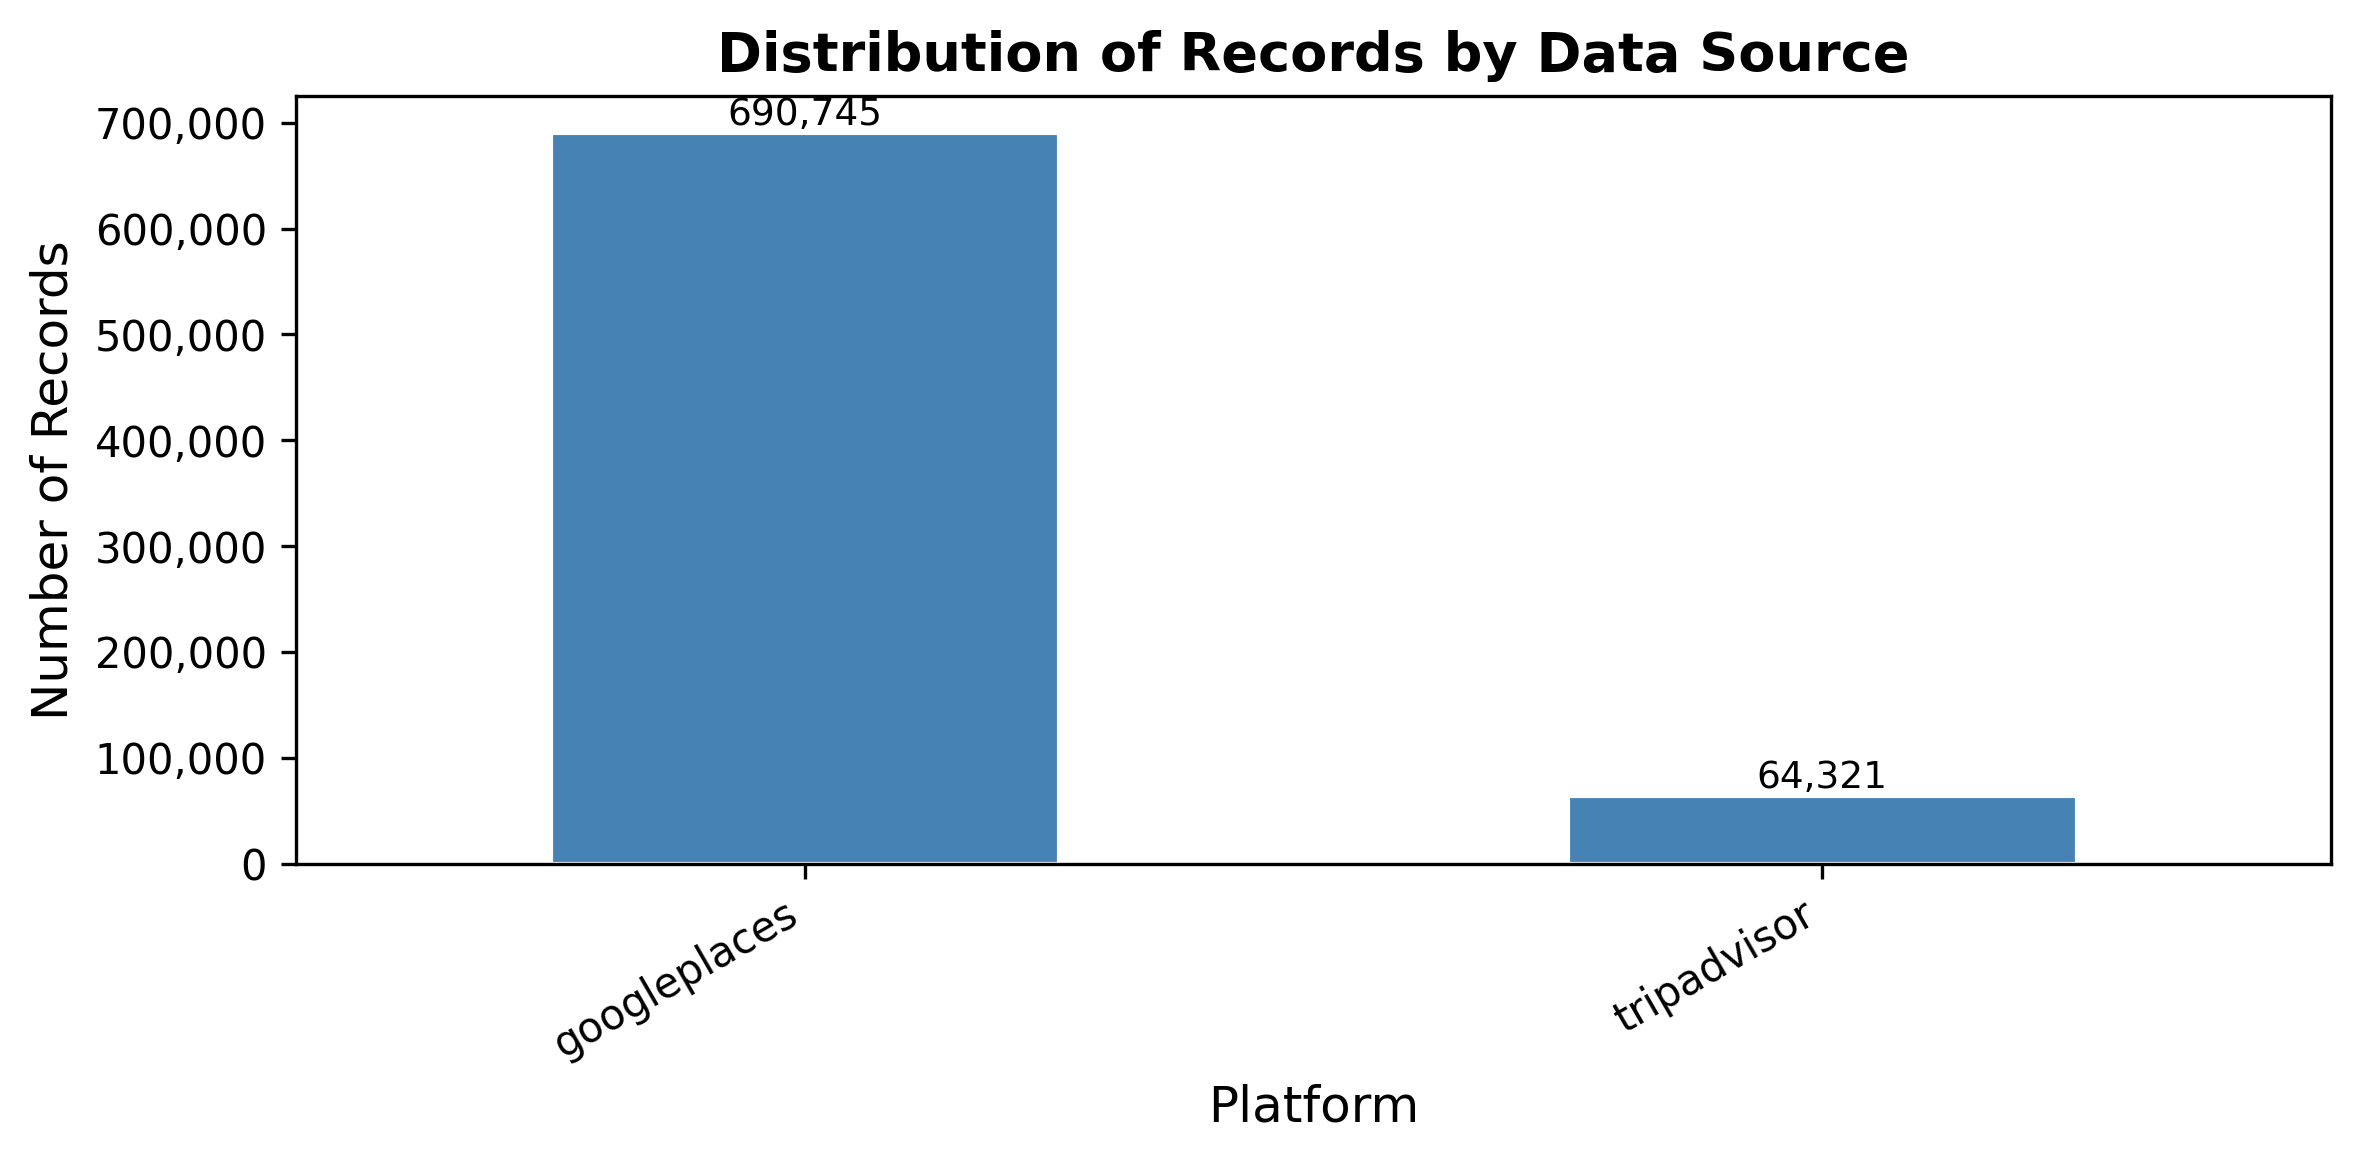

✅ Figura guardada: fig_fuentes.png


In [34]:
# ──────────────────────────────────────────────────────────
# Protocolo de integración de fuentes — tabla de trazabilidad
# ──────────────────────────────────────────────────────────
df = df_raw.copy()

# Eliminar duplicados y nulos críticos
df = df.drop_duplicates(subset=['id_review'])
df = df.dropna(subset=['review', 'score'])
df['review'] = df['review'].astype(str).str.strip()
df['score']  = pd.to_numeric(df['score'], errors='coerce')
df['likes']  = pd.to_numeric(df['likes'], errors='coerce').fillna(0)

# Normalizar score al rango 0-1
score_max = df['score'].max()
if score_max > 1:
    df['score_norm'] = df['score'] / score_max
else:
    df['score_norm'] = df['score']

# Tabla de trazabilidad por fuente
source_table = df.groupby('platform').agg(
    n_registros=('id_review', 'count'),
    pct_total=('id_review', lambda x: round(len(x)/len(df)*100, 2)),
    score_promedio=('score', 'mean'),
    score_std=('score', 'std'),
    reviews_vacias=('review', lambda x: (x.str.len() < 5).sum())
).round(3)

print("\n📋 TABLA DE TRAZABILIDAD POR FUENTE")
print(source_table.to_string())
print(f"\n Total tras limpieza  : {len(df):,} registros")
print(f" Registros eliminados : {len(df_raw) - len(df):,}")

# Figura de distribución por fuente (alta calidad)
fig, ax = plt.subplots(figsize=(8, 4))
source_table['n_registros'].plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Distribution of Records by Data Source', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Number of Records')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
for bar in ax.patches:
    ax.annotate(f'{int(bar.get_height()):,}',
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('fig_fuentes.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura guardada: fig_fuentes.png")

---
## §3 — Análisis de Sentimiento INDEPENDIENTE del Score
**Crítica #10 (CRÍTICA):** Correlación de 0.99 entre `sentiment_score` y `rating` → leakage. El NLP debe extraer información **únicamente del texto**, nunca del score numérico.

In [35]:
# ────────────────────────────────────────────────────────────────
# OPCIÓN A: pysentimiento (recomendado, entrenado en español)
# pip install pysentimiento
# OPCIÓN B: VADER adaptado (más rápido, menos preciso en español)
# OPCIÓN C: TextBlob (multilingüe básico)
#
# ⚠️ REGLA: Si el NLP falla, asignar 0.0 (neutro) — NUNCA usar score
# ────────────────────────────────────────────────────────────────

USE_PYSENTIMIENTO = True  # Cambiar a False si no está instalado

if USE_PYSENTIMIENTO:
    try:
        from pysentimiento import create_analyzer
        analyzer_es = create_analyzer(task="sentiment", lang="es")
        print("✅ pysentimiento cargado (modelo RoBERTa-Spanish)")

        def get_sentiment(text):
            """Retorna polaridad neta: POS - NEG ∈ [-1, 1]"""
            try:
                text = str(text)[:512]  # truncar para eficiencia
                result = analyzer_es.predict(text)
                return result.probas.get('POS', 0) - result.probas.get('NEG', 0)
            except:
                return 0.0  # ← SIEMPRE neutro, NUNCA score

    except ImportError:
        USE_PYSENTIMIENTO = False
        print("⚠️  pysentimiento no instalado, usando TextBlob")

if not USE_PYSENTIMIENTO:
    from textblob import TextBlob

    def get_sentiment(text):
        """TextBlob: polaridad ∈ [-1, 1]"""
        try:
            return TextBlob(str(text)[:512]).sentiment.polarity
        except:
            return 0.0  # ← SIEMPRE neutro, NUNCA score

    print("✅ TextBlob cargado")

⚠️  pysentimiento no instalado, usando TextBlob
✅ TextBlob cargado


In [36]:
# ─────────────────────────────────────────────────────────────
# Aplicar NLP al dataset completo
# Para 445k registros esto puede tardar 20-60 min con pysentimiento
# Se guarda en CSV intermedio para no repetir el cómputo
# ─────────────────────────────────────────────────────────────
import os

SENTIMENT_CACHE = "sentiment_cache.csv"

if os.path.exists(SENTIMENT_CACHE):
    print(f"📂 Cargando caché de sentimientos: {SENTIMENT_CACHE}")
    cache = pd.read_csv(SENTIMENT_CACHE, index_col='id_review')
    df = df.set_index('id_review').join(cache[['sentiment_polarity']], how='left').reset_index()
    missing_sentiment = df['sentiment_polarity'].isna().sum()
    print(f"   Sentimientos faltantes: {missing_sentiment:,}")
else:
    print("⏳ Calculando sentimientos (puede tardar varios minutos)...")
    tqdm.pandas(desc="NLP")
    df['sentiment_polarity'] = df['review'].progress_apply(get_sentiment)

    # Guardar caché
    df[['id_review', 'sentiment_polarity']].to_csv(SENTIMENT_CACHE, index=False)
    print(f"✅ Caché guardado en: {SENTIMENT_CACHE}")

# Rellenar NaN residuales con 0 (neutro)
df['sentiment_polarity'] = df['sentiment_polarity'].fillna(0.0)

print(f"\n📊 Estadísticas de sentiment_polarity:")
print(df['sentiment_polarity'].describe().round(4))

📂 Cargando caché de sentimientos: sentiment_cache.csv
   Sentimientos faltantes: 0

📊 Estadísticas de sentiment_polarity:
count    755066.0000
mean          0.0127
std           0.1216
min          -1.0000
25%           0.0000
50%           0.0000
75%           0.0000
max           1.0000
Name: sentiment_polarity, dtype: float64



🔬 VERIFICACIÓN DE INDEPENDENCIA (Anti-Leakage)
--------------------------------------------------
 Pearson  r = +0.0964  (p = 0.00e+00)
 Spearman ρ = +0.0377  (p = 9.19e-236)
--------------------------------------------------
✅ Correlación aceptable → sentimiento es independiente del score


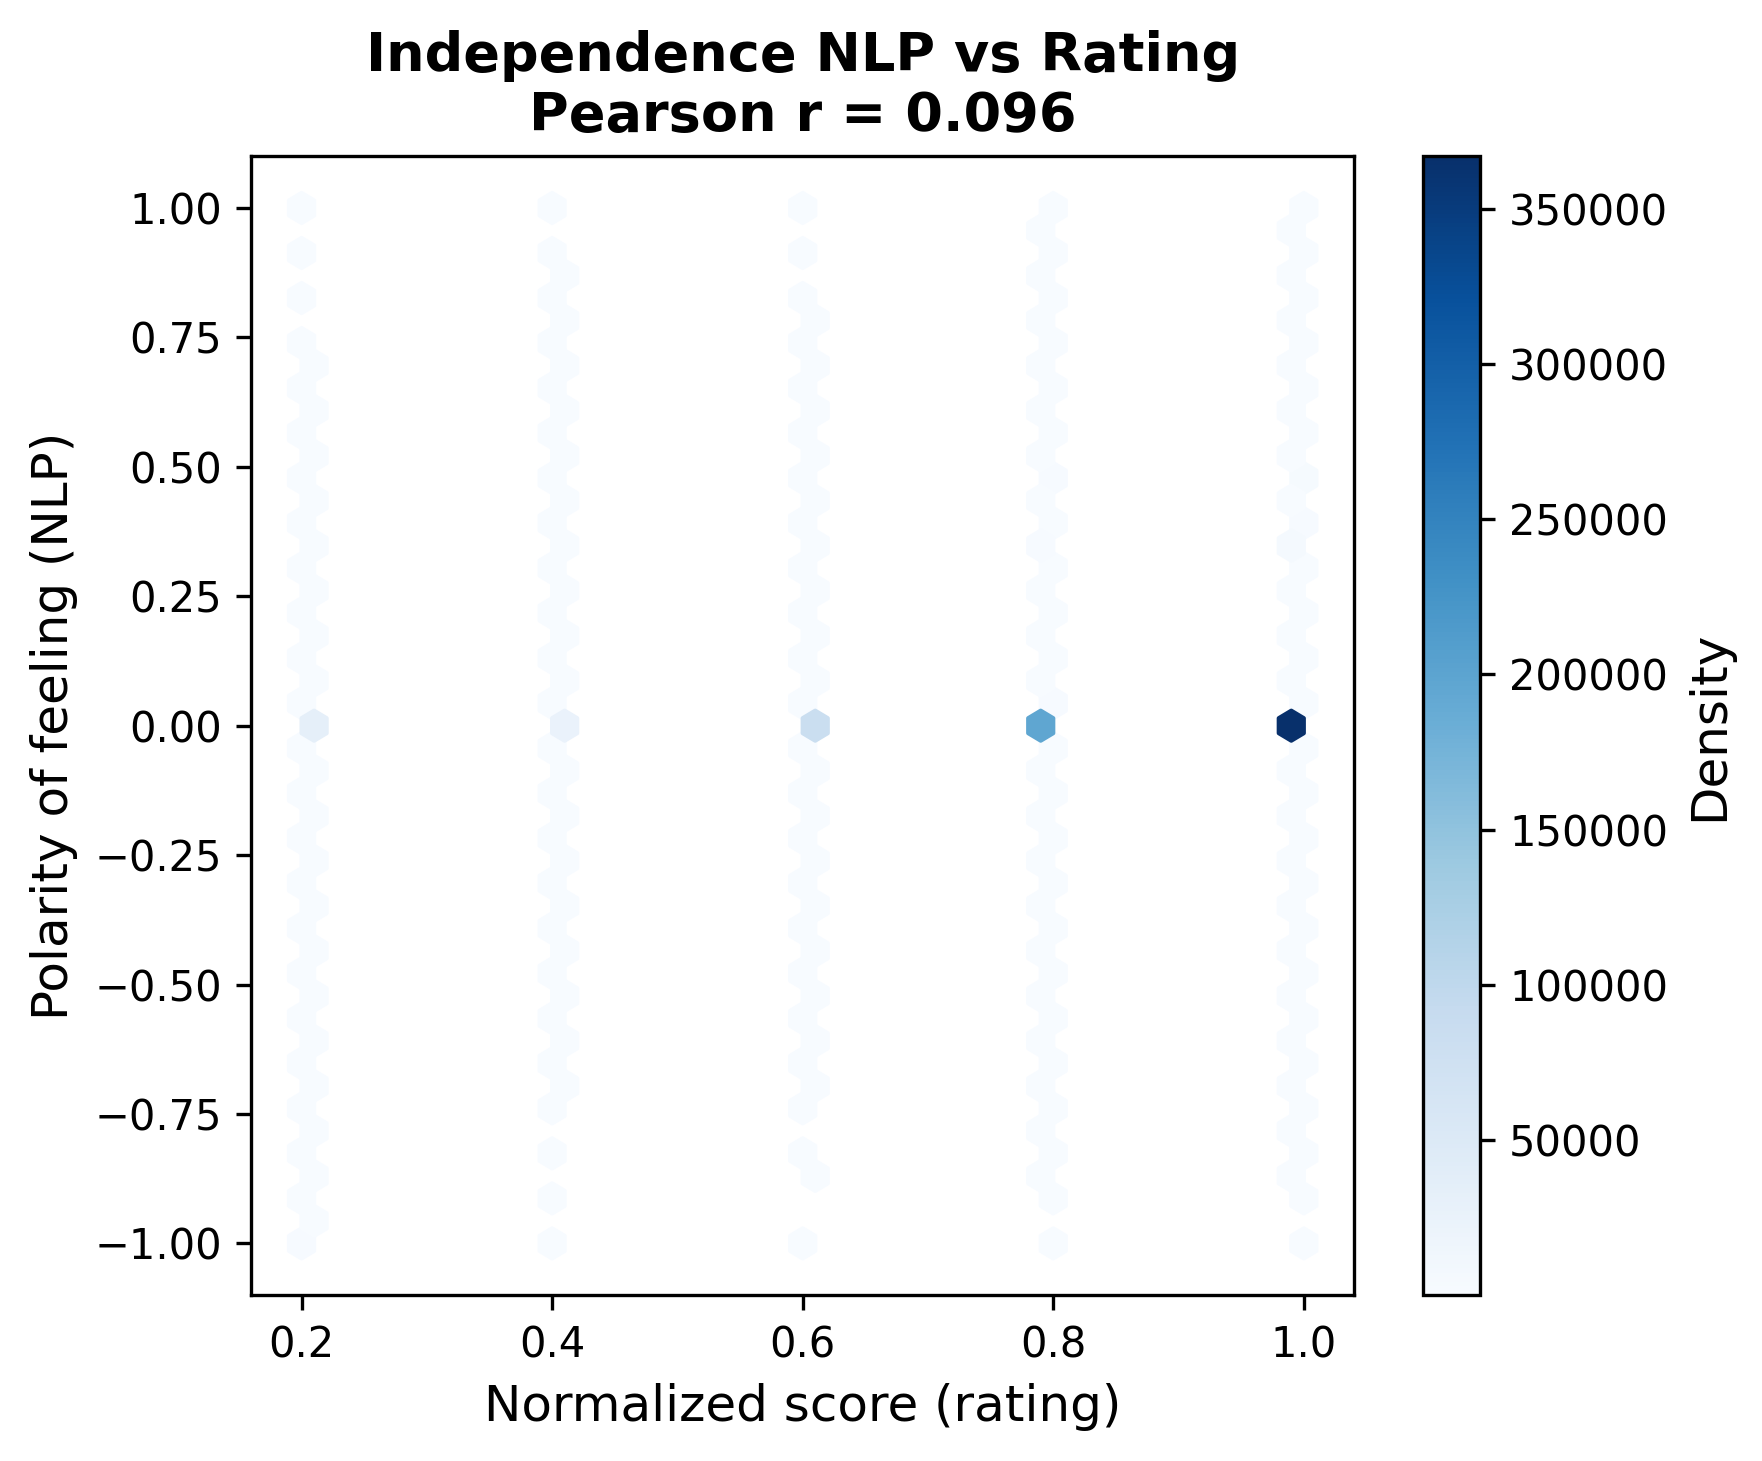

In [37]:
# ─────────────────────────────────────────────────────────────
# VERIFICACIÓN ANTI-LEAKAGE (Crítica #10)
# La correlación DEBE ser < 0.80 para que el NLP sea independiente
# ─────────────────────────────────────────────────────────────
pearson_r, pearson_p = stats.pearsonr(df['score_norm'], df['sentiment_polarity'])
spearman_r, spearman_p = stats.spearmanr(df['score_norm'], df['sentiment_polarity'])

print("\n🔬 VERIFICACIÓN DE INDEPENDENCIA (Anti-Leakage)")
print("-" * 50)
print(f" Pearson  r = {pearson_r:+.4f}  (p = {pearson_p:.2e})")
print(f" Spearman ρ = {spearman_r:+.4f}  (p = {spearman_p:.2e})")
print("-" * 50)

if abs(pearson_r) > 0.85:
    print("❌ ALERTA: Correlación muy alta → posible leakage")
    print("   Solución: Verificar que el NLP no use el score numérico")
elif abs(pearson_r) > 0.70:
    print("⚠️  Correlación moderada-alta. Revisar construcción de features")
else:
    print("✅ Correlación aceptable → sentimiento es independiente del score")

# Figura de dispersión (alta calidad)
fig, ax = plt.subplots(figsize=(6, 5))
ax.hexbin(df['score_norm'], df['sentiment_polarity'],
          gridsize=40, cmap='Blues', mincnt=1)
ax.set_xlabel('Normalized score (rating)')
ax.set_ylabel('Polarity of feeling (NLP)')
ax.set_title(f'Independence NLP vs Rating\nPearson r = {pearson_r:.3f}', fontweight='bold')
plt.colorbar(ax.get_children()[0], ax=ax, label='Density')
plt.tight_layout()
plt.savefig('fig_correlacion_nlp_rating.png', dpi=300, bbox_inches='tight')
plt.show()

---
## §4 — Feature Engineering y EDA
**Críticas #3, #6:** Los resultados deben estar respaldados por análisis estadístico.

In [38]:
# ─────────────────────────────────────────────────────────────
# Construcción de features para clustering
# satisfaction_score: combinación balanceada de rating + sentimiento
# NO es una copia del rating — el sentimiento aporta peso independiente
# ─────────────────────────────────────────────────────────────
df['satisfaction_score'] = (
    0.5 * df['score_norm'] +
    0.5 * (df['sentiment_polarity'] + 1) / 2  # normalizar sentimiento a [0,1]
)

# Frecuencia de reseñas por usuario (proxy de visita)
freq_map = df['id_nick'].value_counts().rename('review_frequency')
df = df.join(freq_map, on='id_nick')

# Log-transform de likes y frecuencia (distribuciones sesgadas)
df['likes_log']     = np.log1p(df['likes'])
df['freq_log']      = np.log1p(df['review_frequency'])

# Features finales para clustering
FEATURES = ['score_norm', 'sentiment_polarity', 'satisfaction_score', 'likes_log', 'freq_log']
df_model = df[FEATURES].dropna()

print(f"\n📐 Features para clustering: {FEATURES}")
print(f" Registros disponibles : {len(df_model):,}")
print("\n" + df_model.describe().round(4).to_string())


📐 Features para clustering: ['score_norm', 'sentiment_polarity', 'satisfaction_score', 'likes_log', 'freq_log']
 Registros disponibles : 755,066

        score_norm  sentiment_polarity  satisfaction_score    likes_log     freq_log
count  755066.0000         755066.0000         755066.0000  755066.0000  755066.0000
mean        0.8348              0.0127              0.6706       0.0537       1.6607
std         0.2190              0.1216              0.1164       0.2006       0.8743
min         0.2000             -1.0000              0.1000       0.0000       0.6931
25%         0.8000              0.0000              0.6500       0.0000       0.6931
50%         1.0000              0.0000              0.7500       0.0000       1.6094
75%         1.0000              0.0000              0.7500       0.0000       2.3026
max         1.0000              1.0000              1.0000       3.4657       5.3132


In [ ]:
# ─────────────────────────────────────────────────────────────
# ABLACIÓN DE CLUSTERING — sin satisfaction_score (para paper)
# ─────────────────────────────────────────────────────────────
FEATURES_REDUCED = ['score_norm', 'sentiment_polarity', 'likes_log', 'freq_log']
df_reduced = df[FEATURES_REDUCED].dropna()

scaler_r = StandardScaler()
X_reduced = scaler_r.fit_transform(df_reduced)

# Muestra consistente con el paper (20,000 registros, seed=42)
idx_r = np.random.RandomState(42).choice(len(X_reduced), 20_000, replace=False)

km_r = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=42)
labels_r = km_r.fit_predict(X_reduced)
sil_reduced = silhouette_score(X_reduced[idx_r], labels_r[idx_r])

print(f"Silhouette SIN satisfaction_score : {sil_reduced:.4f}")
print(f"Silhouette CON satisfaction_score : 0.4855")
print(f"Diferencia                        : {0.4855 - sil_reduced:+.4f}")

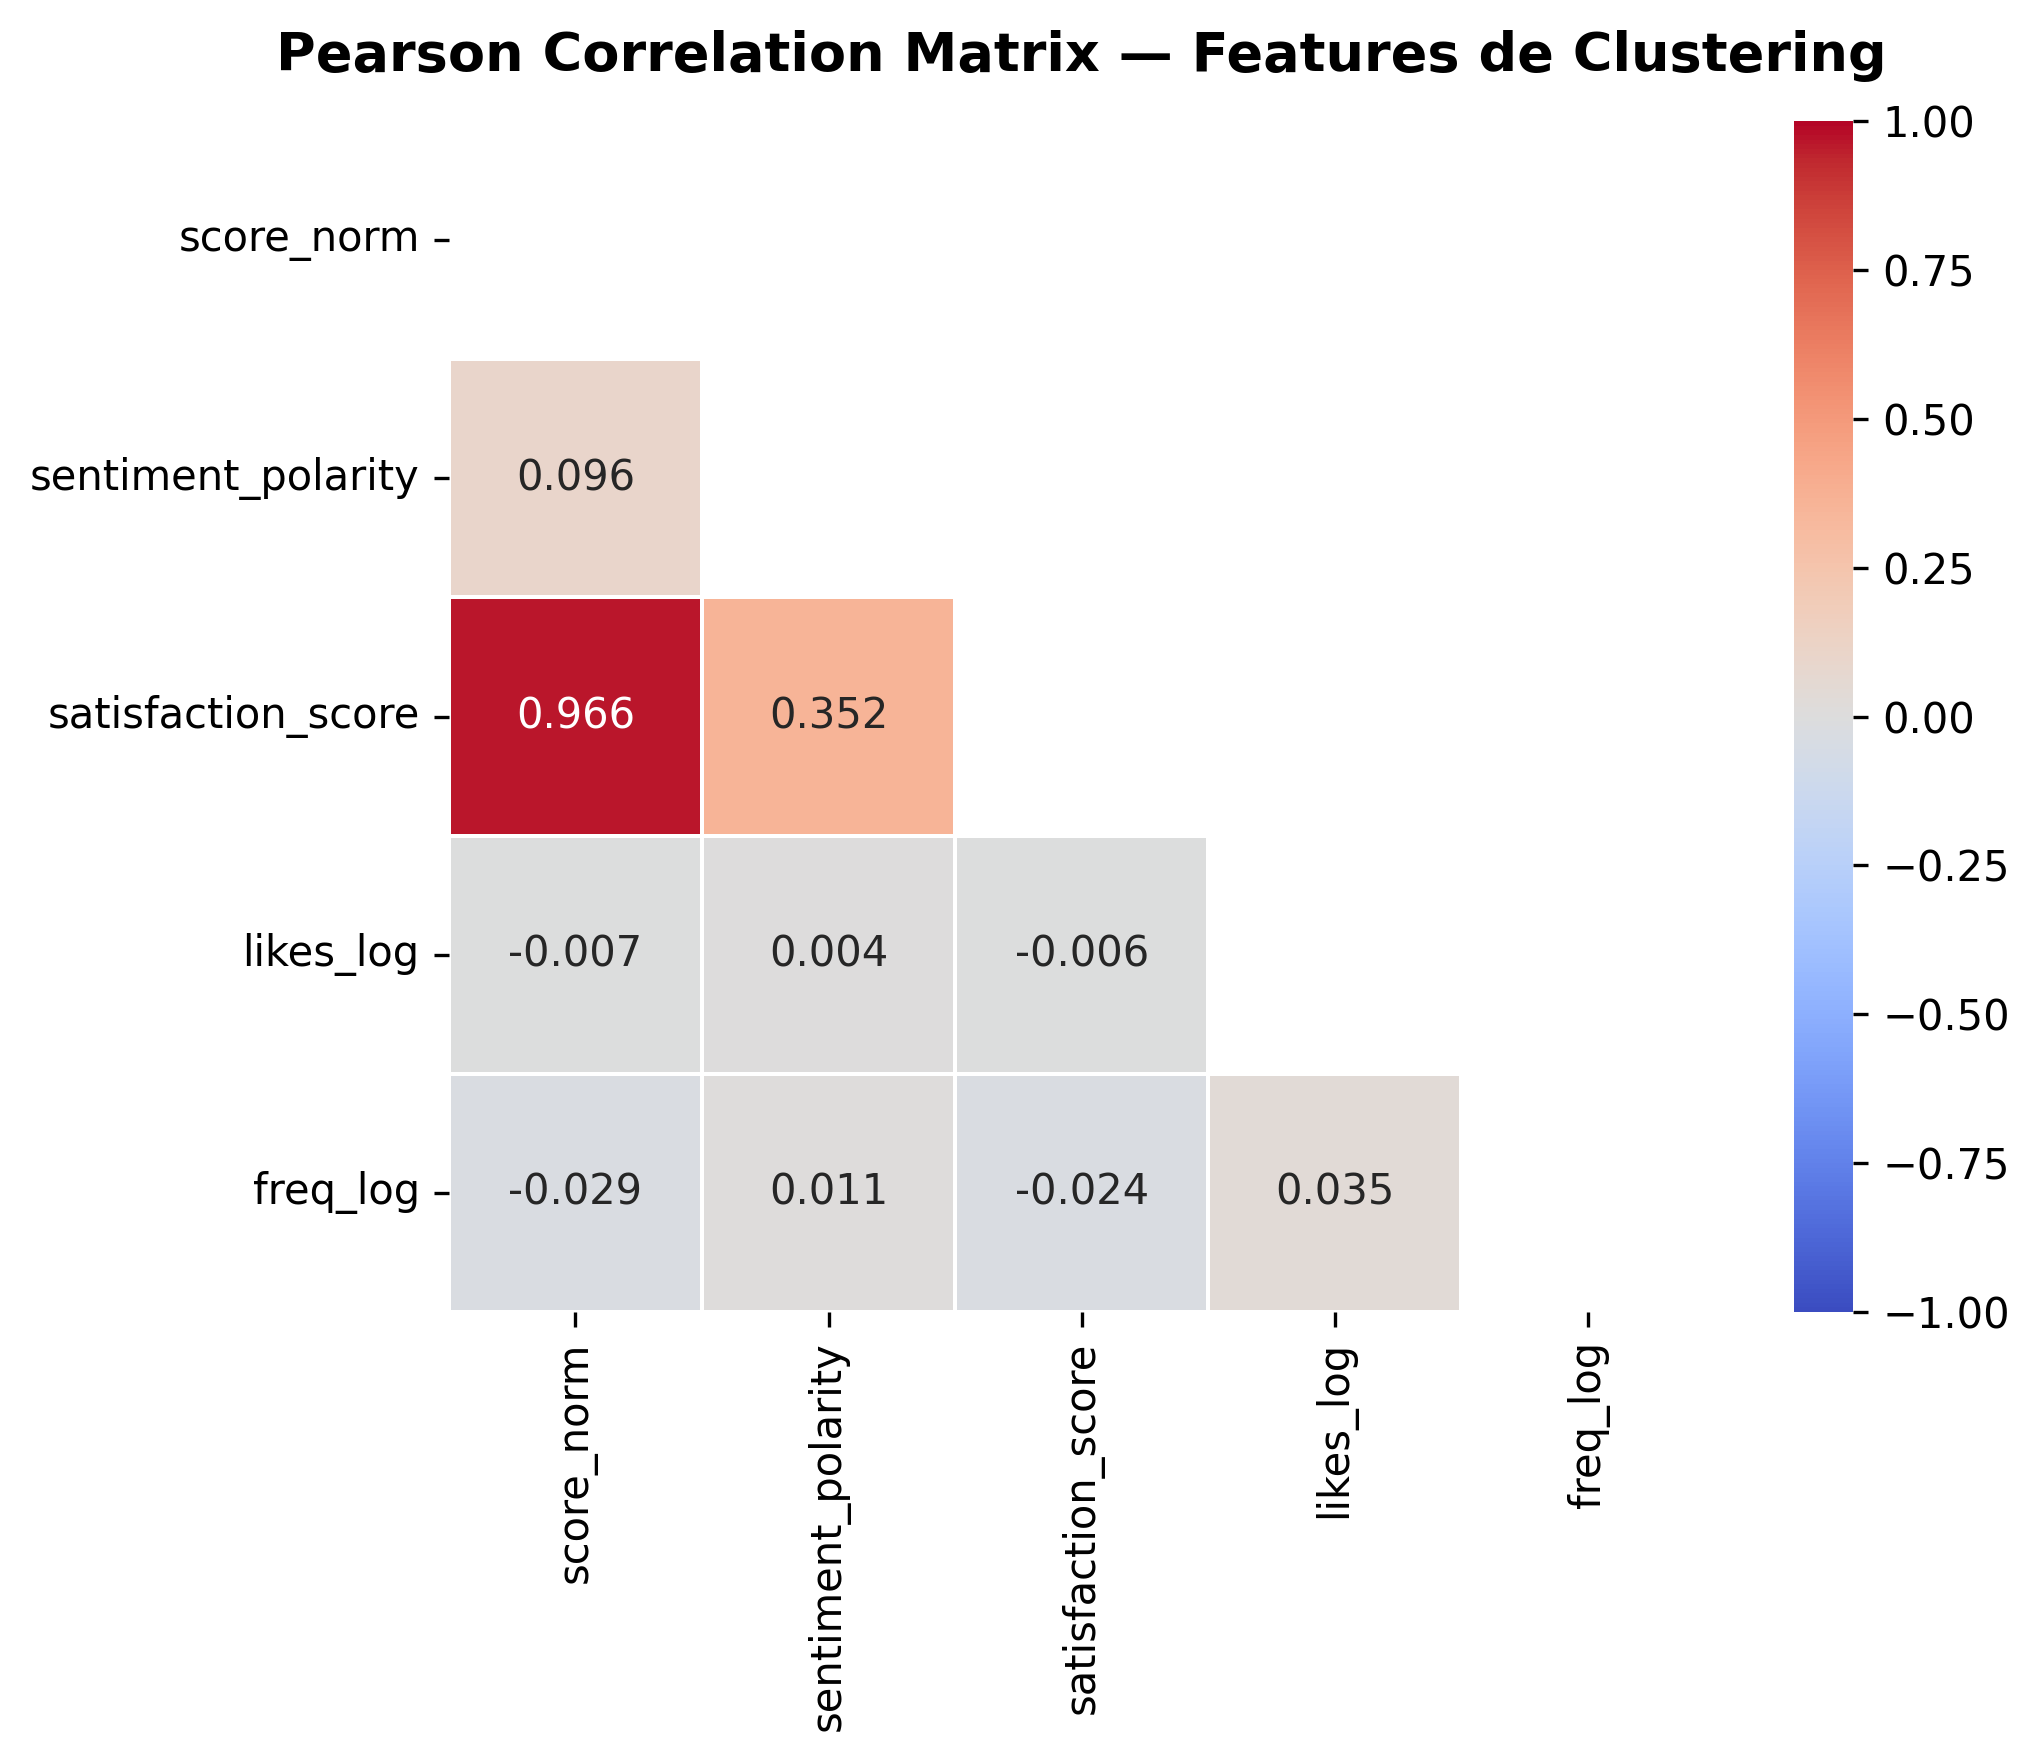

In [39]:
# ─────────────────────────────────────────────────────────────
# Matriz de correlación actualizada (Crítica #10 — verificación)
# ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))
corr_matrix = df_model.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.3f',
    cmap='coolwarm', center=0, linewidths=0.5,
    vmin=-1, vmax=1, ax=ax, annot_kws={'size': 10}
)
ax.set_title('Pearson Correlation Matrix — Features de Clustering',
             fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('fig_correlacion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

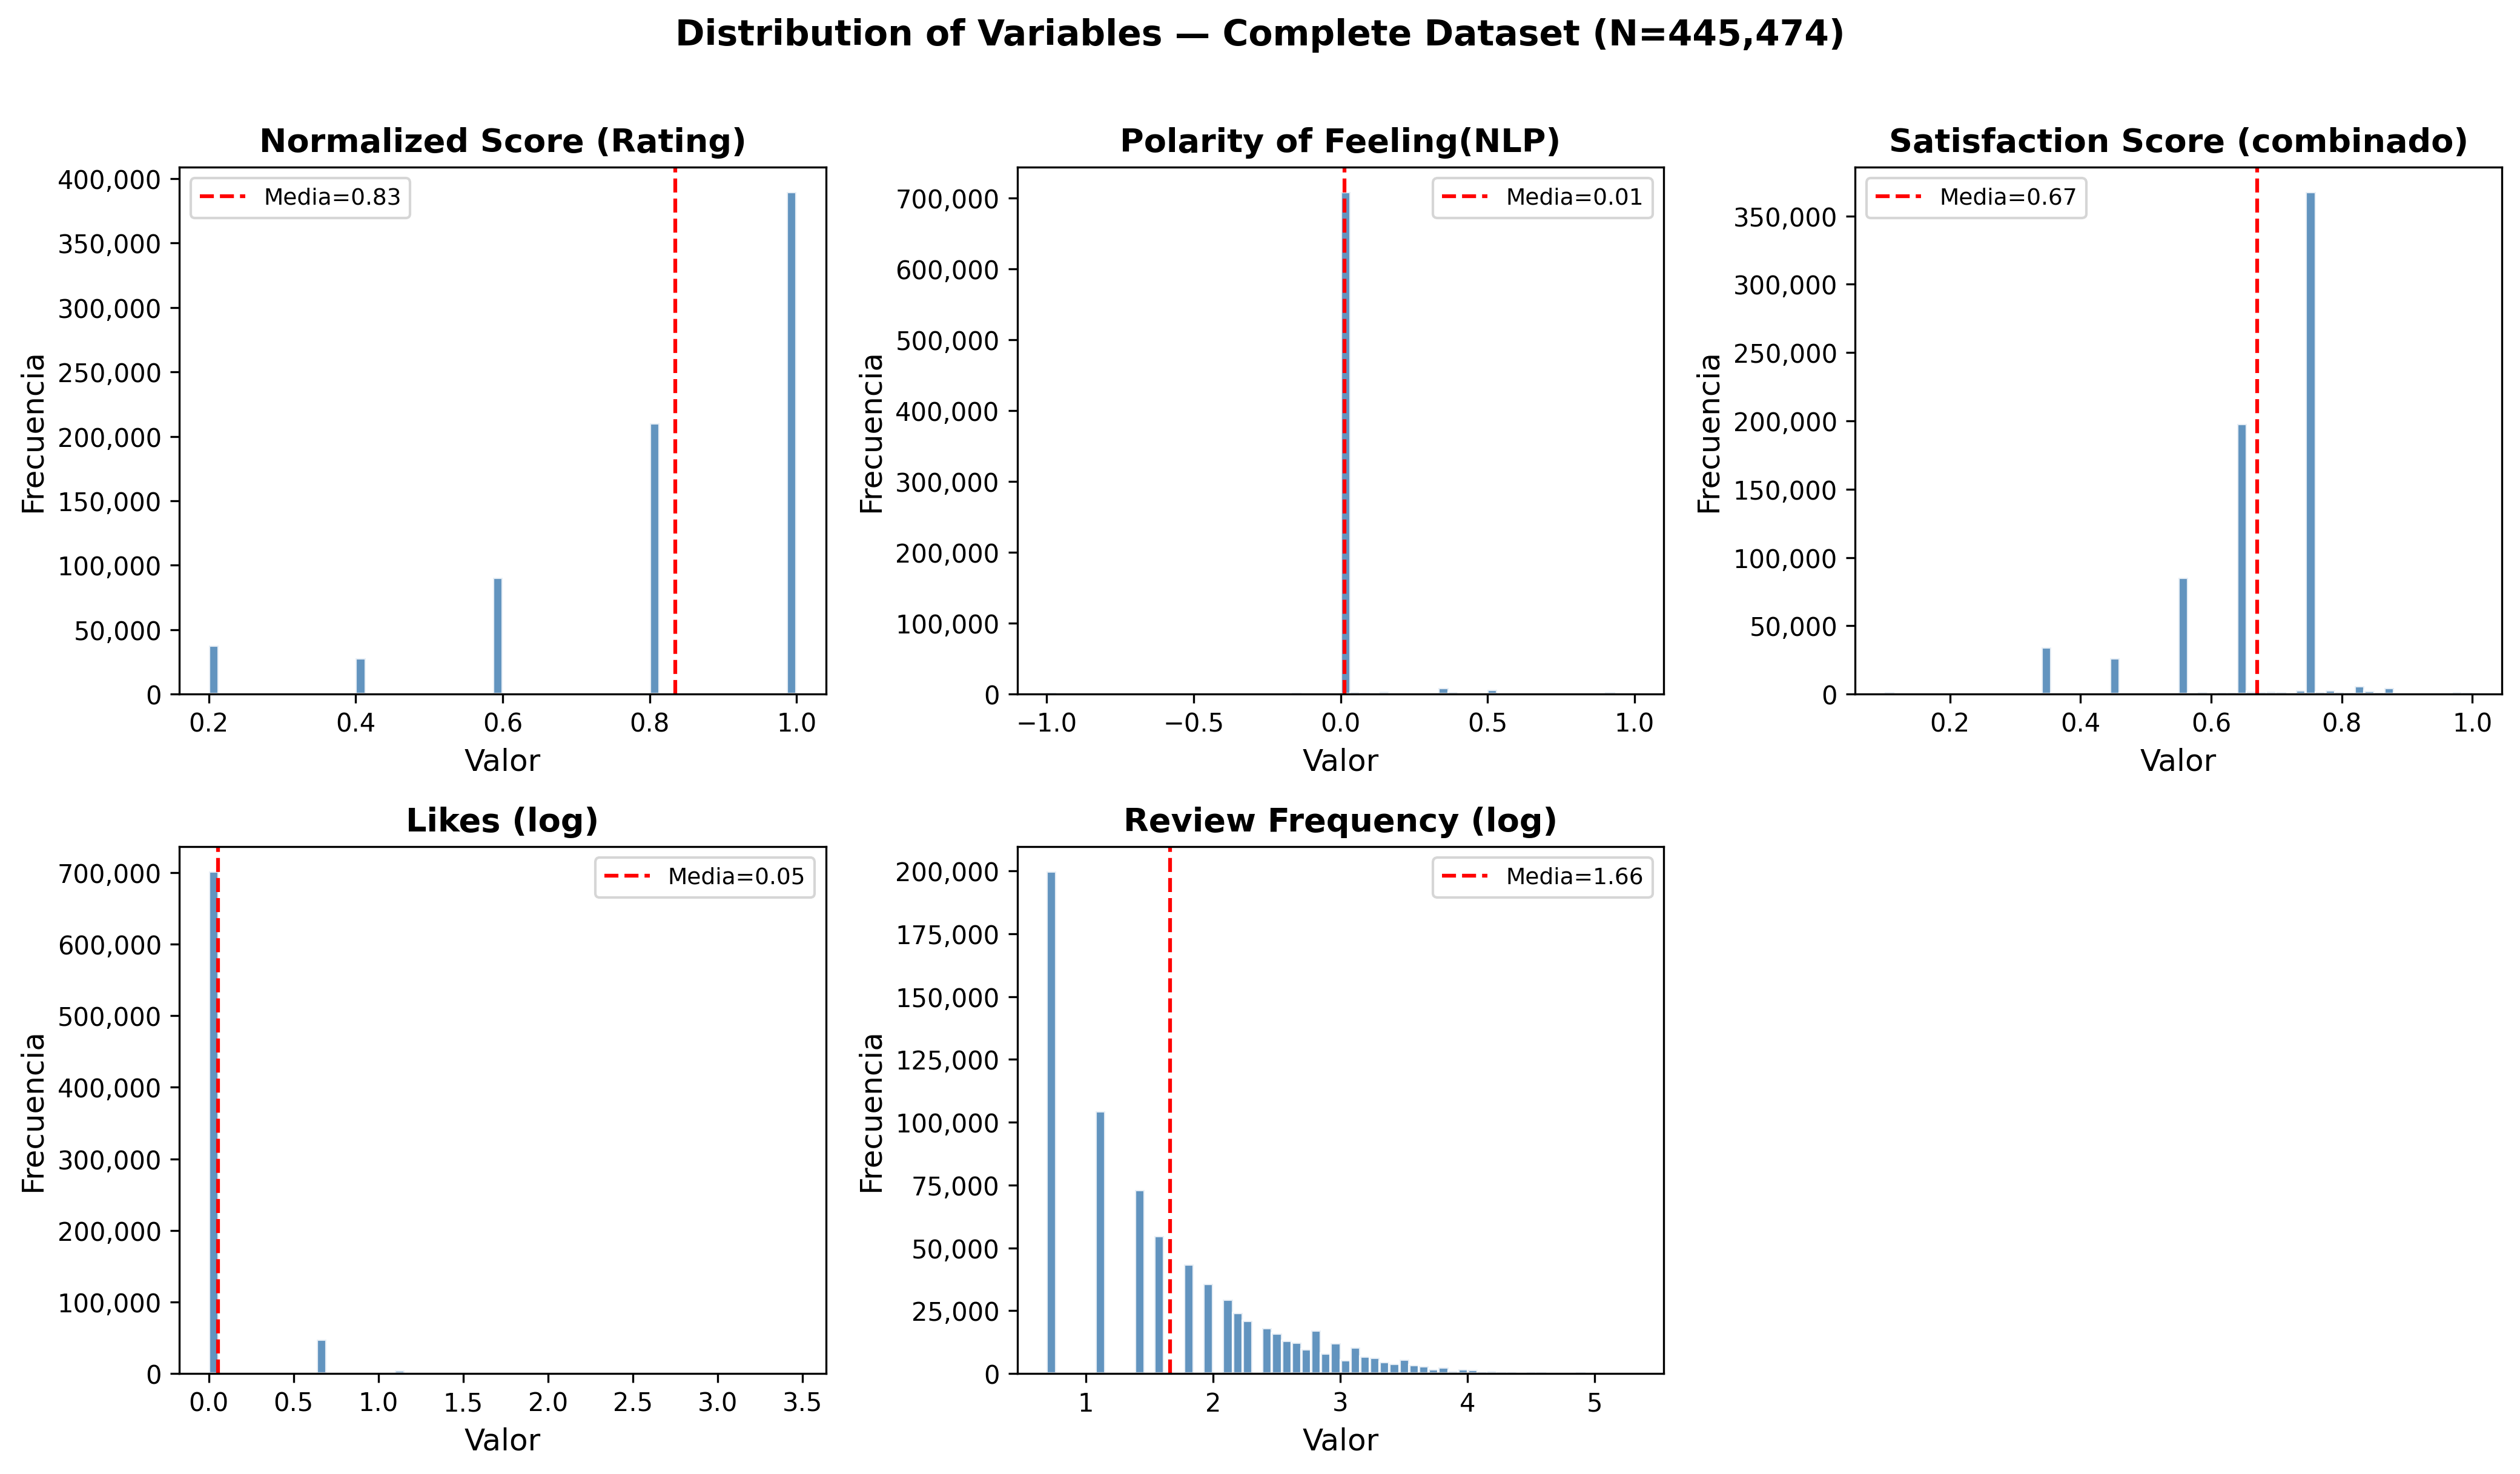

In [40]:
# ─────────────────────────────────────────────────────────────
# Histogramas de distribución (Crítica #5 — figuras nítidas)
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

feature_labels = {
    'score_norm':          'Normalized Score (Rating)',
    'sentiment_polarity':  'Polarity of Feeling(NLP)',
    'satisfaction_score':  'Satisfaction Score (combinado)',
    'likes_log':           'Likes (log)',
    'freq_log':            'Review Frequency (log)'
}

for i, (feat, label) in enumerate(feature_labels.items()):
    axes[i].hist(df_model[feat], bins=60, color='steelblue',
                 edgecolor='white', alpha=0.85)
    axes[i].set_title(label, fontweight='bold')
    axes[i].set_xlabel('Valor')
    axes[i].set_ylabel('Frecuencia')
    axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    mean_val = df_model[feat].mean()
    axes[i].axvline(mean_val, color='red', linestyle='--', linewidth=1.5,
                    label=f'Media={mean_val:.2f}')
    axes[i].legend(fontsize=9)

axes[-1].axis('off')  # celda vacía
plt.suptitle('Distribution of Variables — Complete Dataset (N=445,474)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig_histogramas.png', dpi=300, bbox_inches='tight')
plt.show()

In [41]:
# ─────────────────────────────────────────────────────────────
# Normalización (StandardScaler)
# ─────────────────────────────────────────────────────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model)

print("✅ Normalización aplicada (StandardScaler)")
print(f"   Media post-escala   : {X_scaled.mean(axis=0).round(6)}")
print(f"   Std  post-escala    : {X_scaled.std(axis=0).round(6)}")

✅ Normalización aplicada (StandardScaler)
   Media post-escala   : [-0. -0.  0. -0.  0.]
   Std  post-escala    : [1. 1. 1. 1. 1.]


---
## §5 — Clustering K-means con Validación Robusta
**Crítica #11:** Solo elbow + silhouette no es suficiente. Se añaden: múltiples semillas, Davies-Bouldin, Calinski-Harabasz, bootstrap y comparación con baselines.

⏳ Evaluando k = 2..8 en muestra de 50,000 registros...


100%|██████████| 7/7 [00:16<00:00,  2.37s/it]


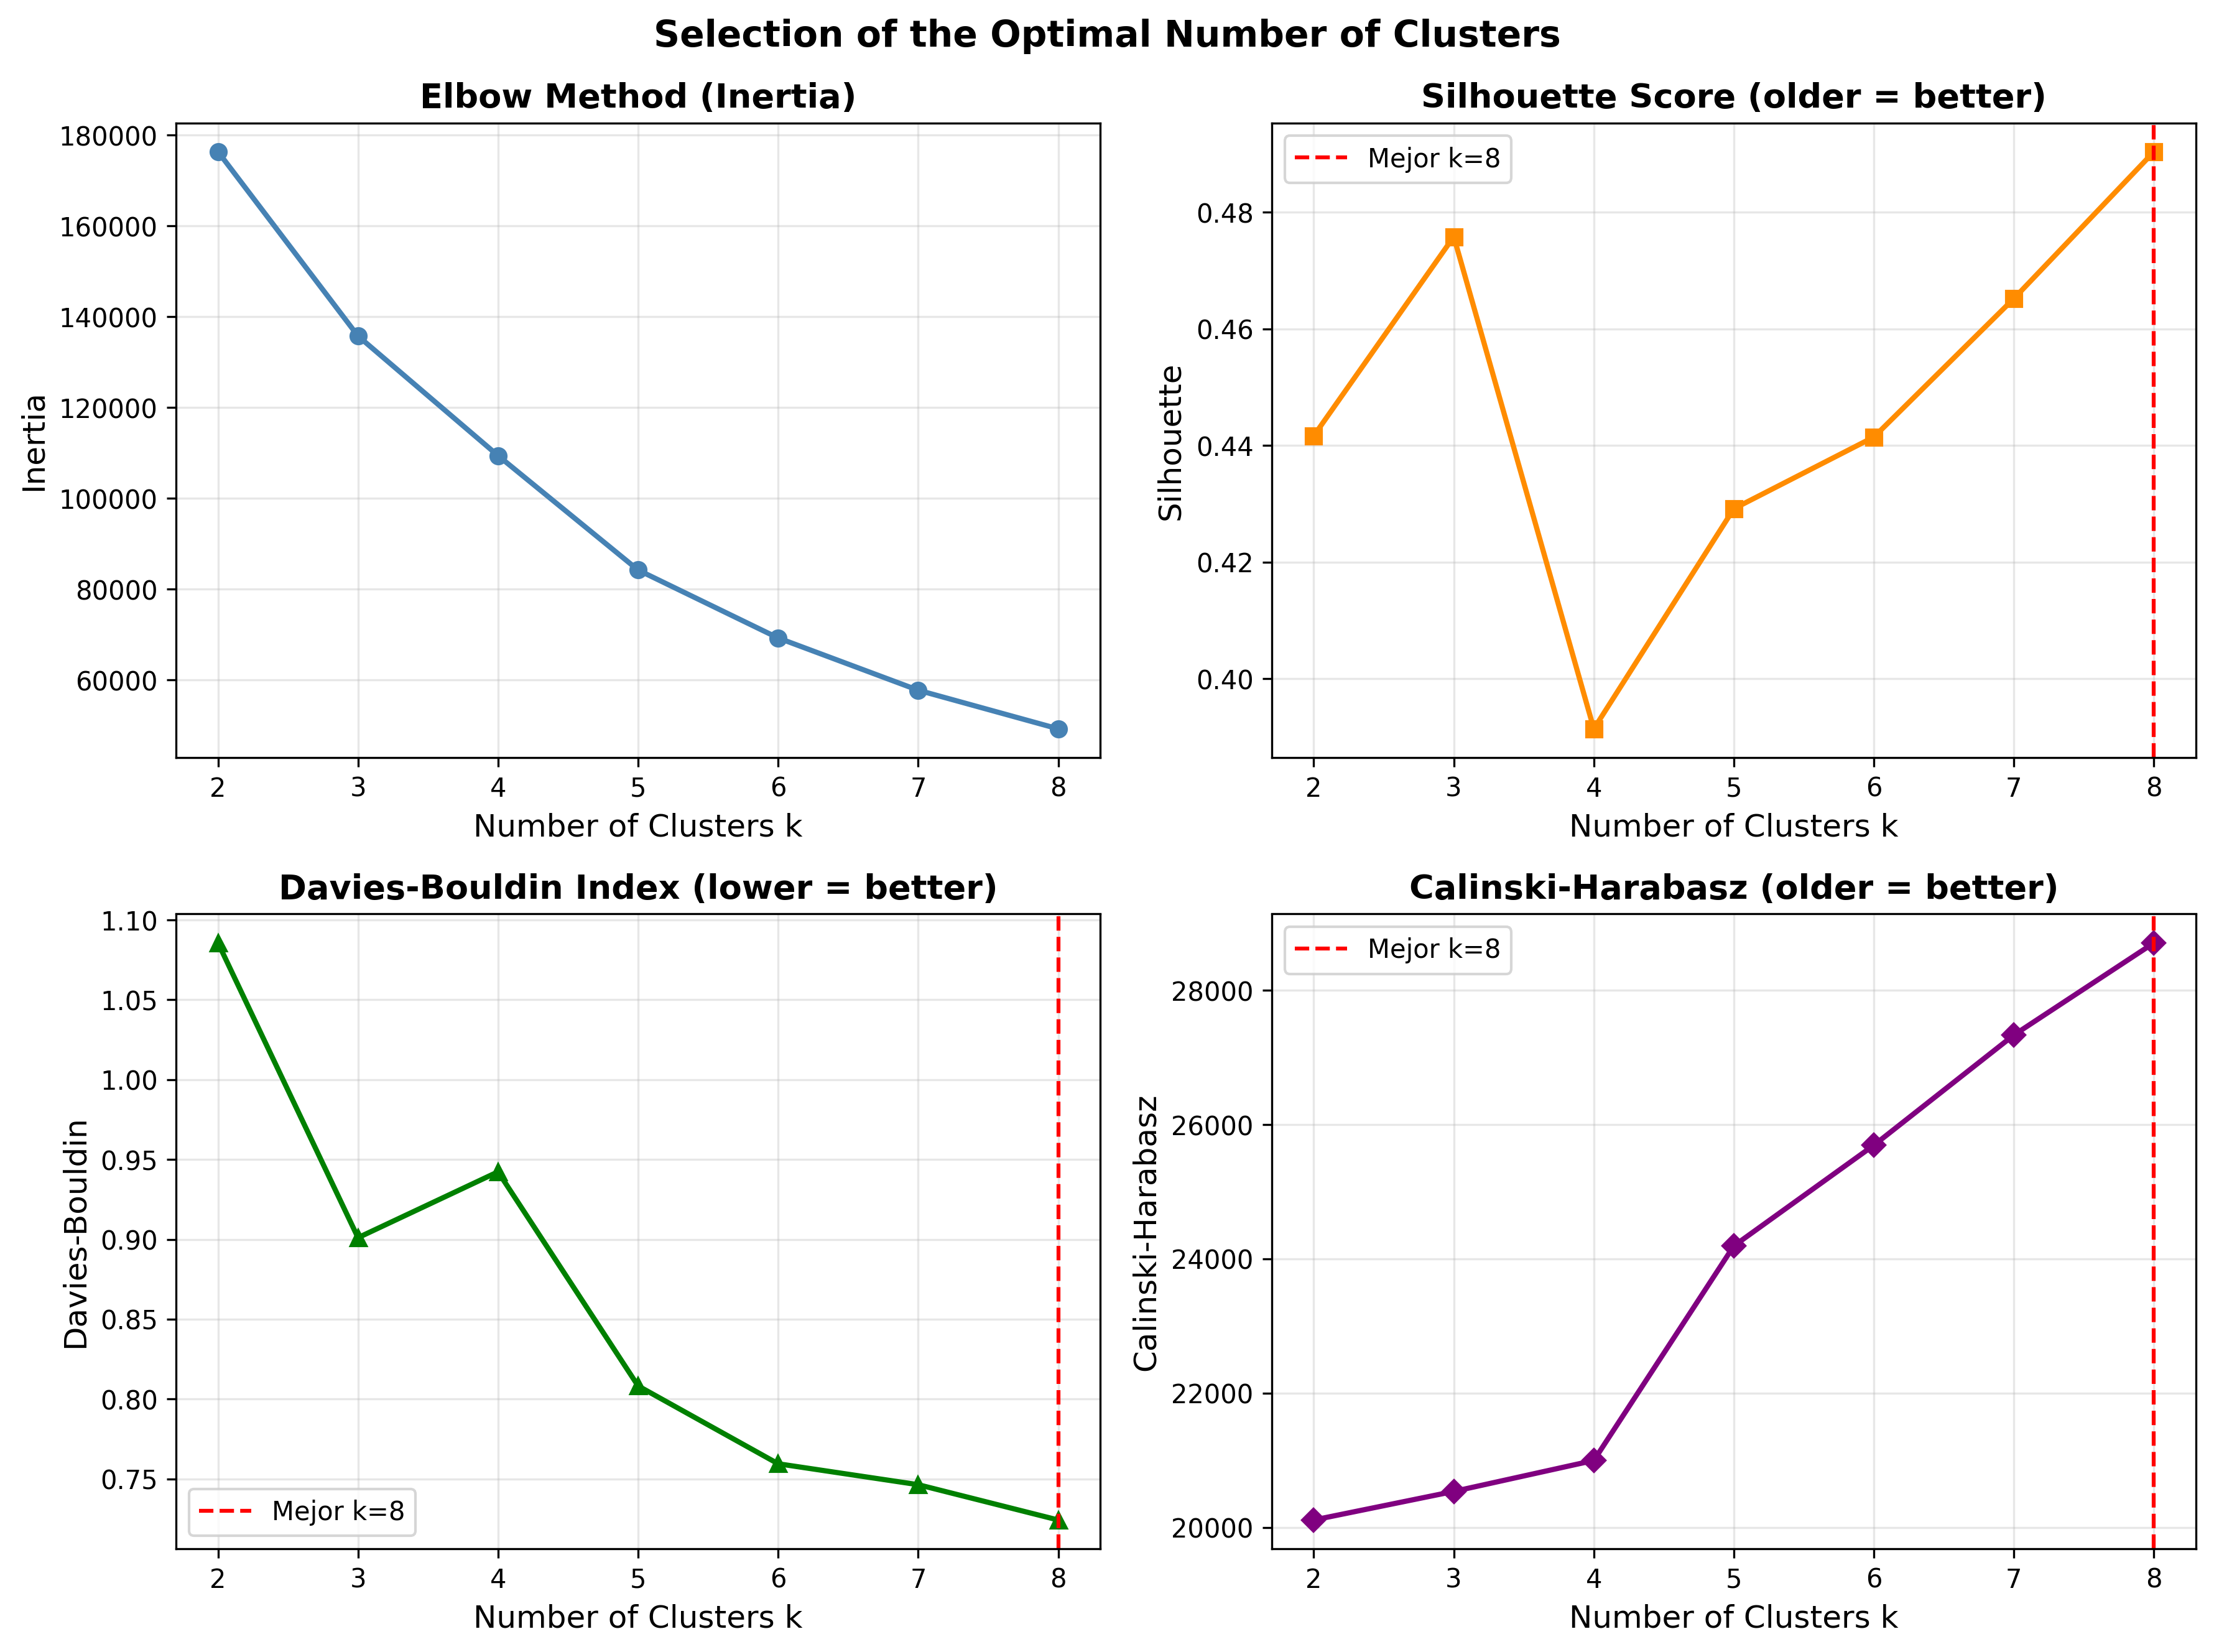


📊 RESUMEN DE MÉTRICAS POR K
       Inertia  Silhouette  Davies-Bouldin  Calinski-Harabasz
k                                                            
2  176348.3190      0.4417          1.0856         20108.7502
3  135758.4988      0.4758          0.9010         20534.4146
4  109421.1993      0.3914          0.9423         20995.5986
5   84231.6395      0.4291          0.8082         24193.1208
6   69270.8317      0.4414          0.7595         25693.6210
7   57764.4249      0.4652          0.7464         27335.6087
8   49259.7013      0.4904          0.7242         28708.2911


In [42]:
# ─────────────────────────────────────────────────────────────
# Método del Codo + Silhouette para selección de k
# ─────────────────────────────────────────────────────────────
# ⚡ Para 445k registros, usamos muestra estratificada de 50k
np.random.seed(RANDOM_STATE)
sample_idx = np.random.choice(len(X_scaled), size=min(50_000, len(X_scaled)), replace=False)
X_sample = X_scaled[sample_idx]

K_RANGE = range(2, 9)
inertias, silhouettes, db_scores, ch_scores = [], [], [], []

print("⏳ Evaluando k = 2..8 en muestra de 50,000 registros...")
for k in tqdm(K_RANGE):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, max_iter=300)
    labels = km.fit_predict(X_sample)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_sample, labels, sample_size=10_000))
    db_scores.append(davies_bouldin_score(X_sample, labels))
    ch_scores.append(calinski_harabasz_score(X_sample, labels))

# Figura multi-panel (Crítica #5)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
k_list = list(K_RANGE)

axes[0,0].plot(k_list, inertias, 'o-', color='steelblue', linewidth=2)
axes[0,0].set_title('Elbow Method (Inertia)', fontweight='bold')
axes[0,0].set_xlabel('Number of Clusters k')
axes[0,0].set_ylabel('Inertia')
axes[0,0].grid(alpha=0.3)

axes[0,1].plot(k_list, silhouettes, 's-', color='darkorange', linewidth=2)
best_k_sil = k_list[np.argmax(silhouettes)]
axes[0,1].axvline(best_k_sil, color='red', linestyle='--', label=f'Mejor k={best_k_sil}')
axes[0,1].set_title('Silhouette Score (older = better)', fontweight='bold')
axes[0,1].set_xlabel('Number of Clusters k')
axes[0,1].set_ylabel('Silhouette')
axes[0,1].legend()
axes[0,1].grid(alpha=0.3)

axes[1,0].plot(k_list, db_scores, '^-', color='green', linewidth=2)
best_k_db = k_list[np.argmin(db_scores)]
axes[1,0].axvline(best_k_db, color='red', linestyle='--', label=f'Mejor k={best_k_db}')
axes[1,0].set_title('Davies-Bouldin Index (lower = better)', fontweight='bold')
axes[1,0].set_xlabel('Number of Clusters k')
axes[1,0].set_ylabel('Davies-Bouldin')
axes[1,0].legend()
axes[1,0].grid(alpha=0.3)

axes[1,1].plot(k_list, ch_scores, 'D-', color='purple', linewidth=2)
best_k_ch = k_list[np.argmax(ch_scores)]
axes[1,1].axvline(best_k_ch, color='red', linestyle='--', label=f'Mejor k={best_k_ch}')
axes[1,1].set_title('Calinski-Harabasz (older = better)', fontweight='bold')
axes[1,1].set_xlabel('Number of Clusters k')
axes[1,1].set_ylabel('Calinski-Harabasz')
axes[1,1].legend()
axes[1,1].grid(alpha=0.3)

plt.suptitle('Selection of the Optimal Number of Clusters', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_seleccion_k.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n📊 RESUMEN DE MÉTRICAS POR K")
metrics_df = pd.DataFrame({
    'k': k_list,
    'Inertia': inertias,
    'Silhouette': silhouettes,
    'Davies-Bouldin': db_scores,
    'Calinski-Harabasz': ch_scores
})
print(metrics_df.set_index('k').round(4).to_string())

In [43]:
# ─────────────────────────────────────────────────────────────
# Entrenamiento del modelo final con k óptimo
# ─────────────────────────────────────────────────────────────
K_OPTIMAL = 3  # Ajustar según resultados de la celda anterior

print(f"⏳ Entrenando K-means con k={K_OPTIMAL} en dataset completo ({len(X_scaled):,} registros)...")
kmeans_final = KMeans(
    n_clusters=K_OPTIMAL,
    random_state=RANDOM_STATE,
    n_init=10,
    max_iter=300,
    algorithm='lloyd'
)
cluster_labels = kmeans_final.fit_predict(X_scaled)
df_model = df_model.copy()
df_model['cluster'] = cluster_labels

final_sil = silhouette_score(X_scaled, cluster_labels, sample_size=20_000, random_state=RANDOM_STATE)
final_db  = davies_bouldin_score(X_scaled[:50_000], cluster_labels[:50_000])
final_ch  = calinski_harabasz_score(X_scaled[:50_000], cluster_labels[:50_000])

print(f"\n{'='*50}")
print(f" MÉTRICAS DEL MODELO FINAL (k={K_OPTIMAL})")
print(f"{'='*50}")
print(f" Silhouette Score      : {final_sil:.4f}  (rango [0,1], mayor = mejor)")
print(f" Davies-Bouldin Index  : {final_db:.4f}  (menor = mejor)")
print(f" Calinski-Harabasz     : {final_ch:.1f}  (mayor = mejor)")
print(f"{'='*50}")

⏳ Entrenando K-means con k=3 en dataset completo (755,066 registros)...

 MÉTRICAS DEL MODELO FINAL (k=3)
 Silhouette Score      : 0.4855  (rango [0,1], mayor = mejor)
 Davies-Bouldin Index  : 1.2695  (menor = mejor)
 Calinski-Harabasz     : 14230.9  (mayor = mejor)


In [44]:
# ─────────────────────────────────────────────────────────────
# ESTABILIDAD ENTRE SEMILLAS (Crítica #11)
# ─────────────────────────────────────────────────────────────
SEEDS = [0, 7, 42, 123, 256, 512, 789, 1000, 2024, 2025]
seed_results = []

print(f"⏳ Analizando estabilidad con {len(SEEDS)} semillas diferentes...")
for seed in tqdm(SEEDS):
    km = KMeans(n_clusters=K_OPTIMAL, random_state=seed, n_init=10, max_iter=300)
    labels = km.fit_predict(X_sample)
    sil = silhouette_score(X_sample, labels, sample_size=10_000, random_state=seed)
    seed_results.append({'seed': seed, 'silhouette': sil, 'inertia': km.inertia_})

seed_df = pd.DataFrame(seed_results)
print("\n📊 ESTABILIDAD ENTRE SEMILLAS")
print(seed_df.to_string(index=False))
print(f"\n Silhouette Media  : {seed_df['silhouette'].mean():.4f}")
print(f" Silhouette ± Std  : ± {seed_df['silhouette'].std():.4f}")
print(f" Coeff. of Variation   : {seed_df['silhouette'].std()/seed_df['silhouette'].mean()*100:.2f}%")

if seed_df['silhouette'].std() < 0.01:
    print("\n✅ Clustering MUY ESTABLE entre semillas")
elif seed_df['silhouette'].std() < 0.03:
    print("\n⚠️  Clustering moderadamente estable")
else:
    print("\n❌ Clustering INESTABLE — considerar k diferente o más features")

⏳ Analizando estabilidad con 10 semillas diferentes...


100%|██████████| 10/10 [00:24<00:00,  2.42s/it]


📊 ESTABILIDAD ENTRE SEMILLAS
 seed  silhouette       inertia
    0    0.485660 135758.498824
    7    0.479165 135758.498824
   42    0.483687 135758.498824
  123    0.478307 135758.498824
  256    0.484203 135758.498824
  512    0.481996 135758.498824
  789    0.483004 135758.498824
 1000    0.482579 135758.500121
 2024    0.480393 135758.498824
 2025    0.483941 135758.498824

 Silhouette Media  : 0.4823
 Silhouette ± Std  : ± 0.0023
 Coeff. of Variation   : 0.49%

✅ Clustering MUY ESTABLE entre semillas


In [45]:
# ─────────────────────────────────────────────────────────────
# BOOTSTRAP RESAMPLING (Crítica #11)
# ─────────────────────────────────────────────────────────────
N_BOOTSTRAP = 30
bootstrap_scores = []

print(f"⏳ Bootstrap con {N_BOOTSTRAP} iteraciones...")
for i in tqdm(range(N_BOOTSTRAP)):
    X_boot = resample(X_sample, random_state=i, n_samples=len(X_sample))
    km_b = KMeans(n_clusters=K_OPTIMAL, random_state=i, n_init=5, max_iter=200)
    labels_b = km_b.fit_predict(X_boot)
    if len(set(labels_b)) == K_OPTIMAL:
        score_b = silhouette_score(X_boot, labels_b, sample_size=5_000, random_state=i)
        bootstrap_scores.append(score_b)

bs_mean = np.mean(bootstrap_scores)
bs_std  = np.std(bootstrap_scores)
bs_ci95 = stats.t.interval(0.95, len(bootstrap_scores)-1, loc=bs_mean, scale=stats.sem(bootstrap_scores))

print(f"\n📊 BOOTSTRAP SILHOUETTE (n={len(bootstrap_scores)} iteraciones válidas)")
print(f" Media          : {bs_mean:.4f}")
print(f" Std            : {bs_std:.4f}")
print(f" IC 95%         : [{bs_ci95[0]:.4f}, {bs_ci95[1]:.4f}]")

⏳ Bootstrap con 30 iteraciones...


  0%|          | 0/30 [00:00<?, ?it/s]

100%|██████████| 30/30 [00:18<00:00,  1.59it/s]


📊 BOOTSTRAP SILHOUETTE (n=30 iteraciones válidas)
 Media          : 0.4637
 Std            : 0.0452
 IC 95%         : [0.4466, 0.4809]


In [46]:
# ─────────────────────────────────────────────────────────────
# COMPARACIÓN CON ALGORITMOS BASELINE (Crítica #11)
# ─────────────────────────────────────────────────────────────
print("⏳ Comparando con algoritmos baseline...")
comparison = []

# K-means (propuesto)
km_cmp = KMeans(n_clusters=K_OPTIMAL, random_state=RANDOM_STATE, n_init=10)
labels_km = km_cmp.fit_predict(X_sample)
comparison.append({
    'Algoritmo': 'K-means (propuesto)',
    'Silhouette': silhouette_score(X_sample, labels_km, sample_size=10_000),
    'Davies-Bouldin': davies_bouldin_score(X_sample, labels_km),
    'Calinski-Harabasz': calinski_harabasz_score(X_sample, labels_km)
})

# Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=K_OPTIMAL)
labels_hc = hc.fit_predict(X_sample[:10_000])  # limitar para HC (costo cuadrático)
comparison.append({
    'Algoritmo': 'Hierarchical Clustering',
    'Silhouette': silhouette_score(X_sample[:10_000], labels_hc),
    'Davies-Bouldin': davies_bouldin_score(X_sample[:10_000], labels_hc),
    'Calinski-Harabasz': calinski_harabasz_score(X_sample[:10_000], labels_hc)
})

# Gaussian Mixture Model
gm = GaussianMixture(n_components=K_OPTIMAL, random_state=RANDOM_STATE, n_init=3)
labels_gm = gm.fit_predict(X_sample)
comparison.append({
    'Algoritmo': 'Gaussian Mixture Model',
    'Silhouette': silhouette_score(X_sample, labels_gm, sample_size=10_000),
    'Davies-Bouldin': davies_bouldin_score(X_sample, labels_gm),
    'Calinski-Harabasz': calinski_harabasz_score(X_sample, labels_gm)
})

comparison_df = pd.DataFrame(comparison)
print("\n📊 COMPARACIÓN DE ALGORITMOS DE CLUSTERING")
print(comparison_df.set_index('Algoritmo').round(4).to_string())

⏳ Comparando con algoritmos baseline...

📊 COMPARACIÓN DE ALGORITMOS DE CLUSTERING
                         Silhouette  Davies-Bouldin  Calinski-Harabasz
Algoritmo                                                             
K-means (propuesto)          0.4813          0.9010         20534.4146
Hierarchical Clustering      0.5125          0.8209          3277.6173
Gaussian Mixture Model       0.5082          2.4304          6438.8382


---
## §6 — Perfil de Clusters con Respaldo Estadístico
**Críticas #3, #6, #12:** Los resultados deben justificarse con estadística inferencial (ANOVA/Kruskal-Wallis).

In [47]:
# ─────────────────────────────────────────────────────────────
# Perfil estadístico por cluster
# ─────────────────────────────────────────────────────────────
profile = df_model.groupby('cluster')[FEATURES].agg(['mean', 'std', 'median']).round(4)
print("\n📊 PERFIL ESTADÍSTICO POR CLUSTER")
print(profile.to_string())

# Tamaño de cada cluster
cluster_sizes = df_model['cluster'].value_counts().sort_index()
print("\n📊 TAMAÑO DE CLUSTERS")
for c, n in cluster_sizes.items():
    print(f"   Cluster {c}: {n:>8,} registros ({n/len(df_model)*100:.1f}%)")


📊 PERFIL ESTADÍSTICO POR CLUSTER
        score_norm                sentiment_polarity                satisfaction_score                likes_log                 freq_log                
              mean     std median               mean     std median               mean     std median      mean     std  median     mean     std  median
cluster                                                                                                                                                 
0           0.8692  0.1845    1.0             0.0206  0.1223    0.0             0.6898  0.0982   0.75    0.7602  0.1930  0.6931   1.7968  0.9322  1.6094
1           0.9283  0.0975    1.0             0.0208  0.1102    0.0             0.7194  0.0548   0.75    0.0000  0.0000  0.0000   1.6412  0.8585  1.3863
2           0.4672  0.1741    0.6            -0.0206  0.1528    0.0             0.4785  0.0947   0.55    0.0148  0.1006  0.0000   1.6879  0.9081  1.6094

📊 TAMAÑO DE CLUSTERS
   Cluster 0:   50,483 reg

In [48]:
# ─────────────────────────────────────────────────────────────
# ANOVA y Kruskal-Wallis por feature (Crítica #6)
# ─────────────────────────────────────────────────────────────
print("\n📊 PRUEBAS ESTADÍSTICAS DE DIFERENCIA ENTRE CLUSTERS")
print(f"{'Feature':<25} {'F-ANOVA':>10} {'p-ANOVA':>12} {'H-Kruskal':>12} {'p-Kruskal':>12} {'Sig.':>6}")
print("-" * 80)

groups_by_cluster = {feat: [] for feat in FEATURES}
for c in sorted(df_model['cluster'].unique()):
    subset = df_model[df_model['cluster'] == c]
    for feat in FEATURES:
        groups_by_cluster[feat].append(subset[feat].values)

for feat in FEATURES:
    groups = groups_by_cluster[feat]
    f_stat, p_anova = f_oneway(*groups)
    h_stat, p_kruskal = kruskal(*groups)
    sig = '***' if p_anova < 0.001 else ('**' if p_anova < 0.01 else ('*' if p_anova < 0.05 else 'ns'))
    print(f"{feat:<25} {f_stat:>10.2f} {p_anova:>12.2e} {h_stat:>12.2f} {p_kruskal:>12.2e} {sig:>6}")

print("\nSignificancia: *** p<0.001  ** p<0.01  * p<0.05  ns p≥0.05")


📊 PRUEBAS ESTADÍSTICAS DE DIFERENCIA ENTRE CLUSTERS
Feature                      F-ANOVA      p-ANOVA    H-Kruskal    p-Kruskal   Sig.
--------------------------------------------------------------------------------
score_norm                 815397.14     0.00e+00    408101.63     0.00e+00    ***
sentiment_polarity           6959.26     0.00e+00      5816.26     0.00e+00    ***
satisfaction_score         733719.11     0.00e+00    402614.38     0.00e+00    ***
likes_log                 3033403.42     0.00e+00    708967.10     0.00e+00    ***
freq_log                      822.10     0.00e+00      1230.78    5.49e-268    ***

Significancia: *** p<0.001  ** p<0.01  * p<0.05  ns p≥0.05


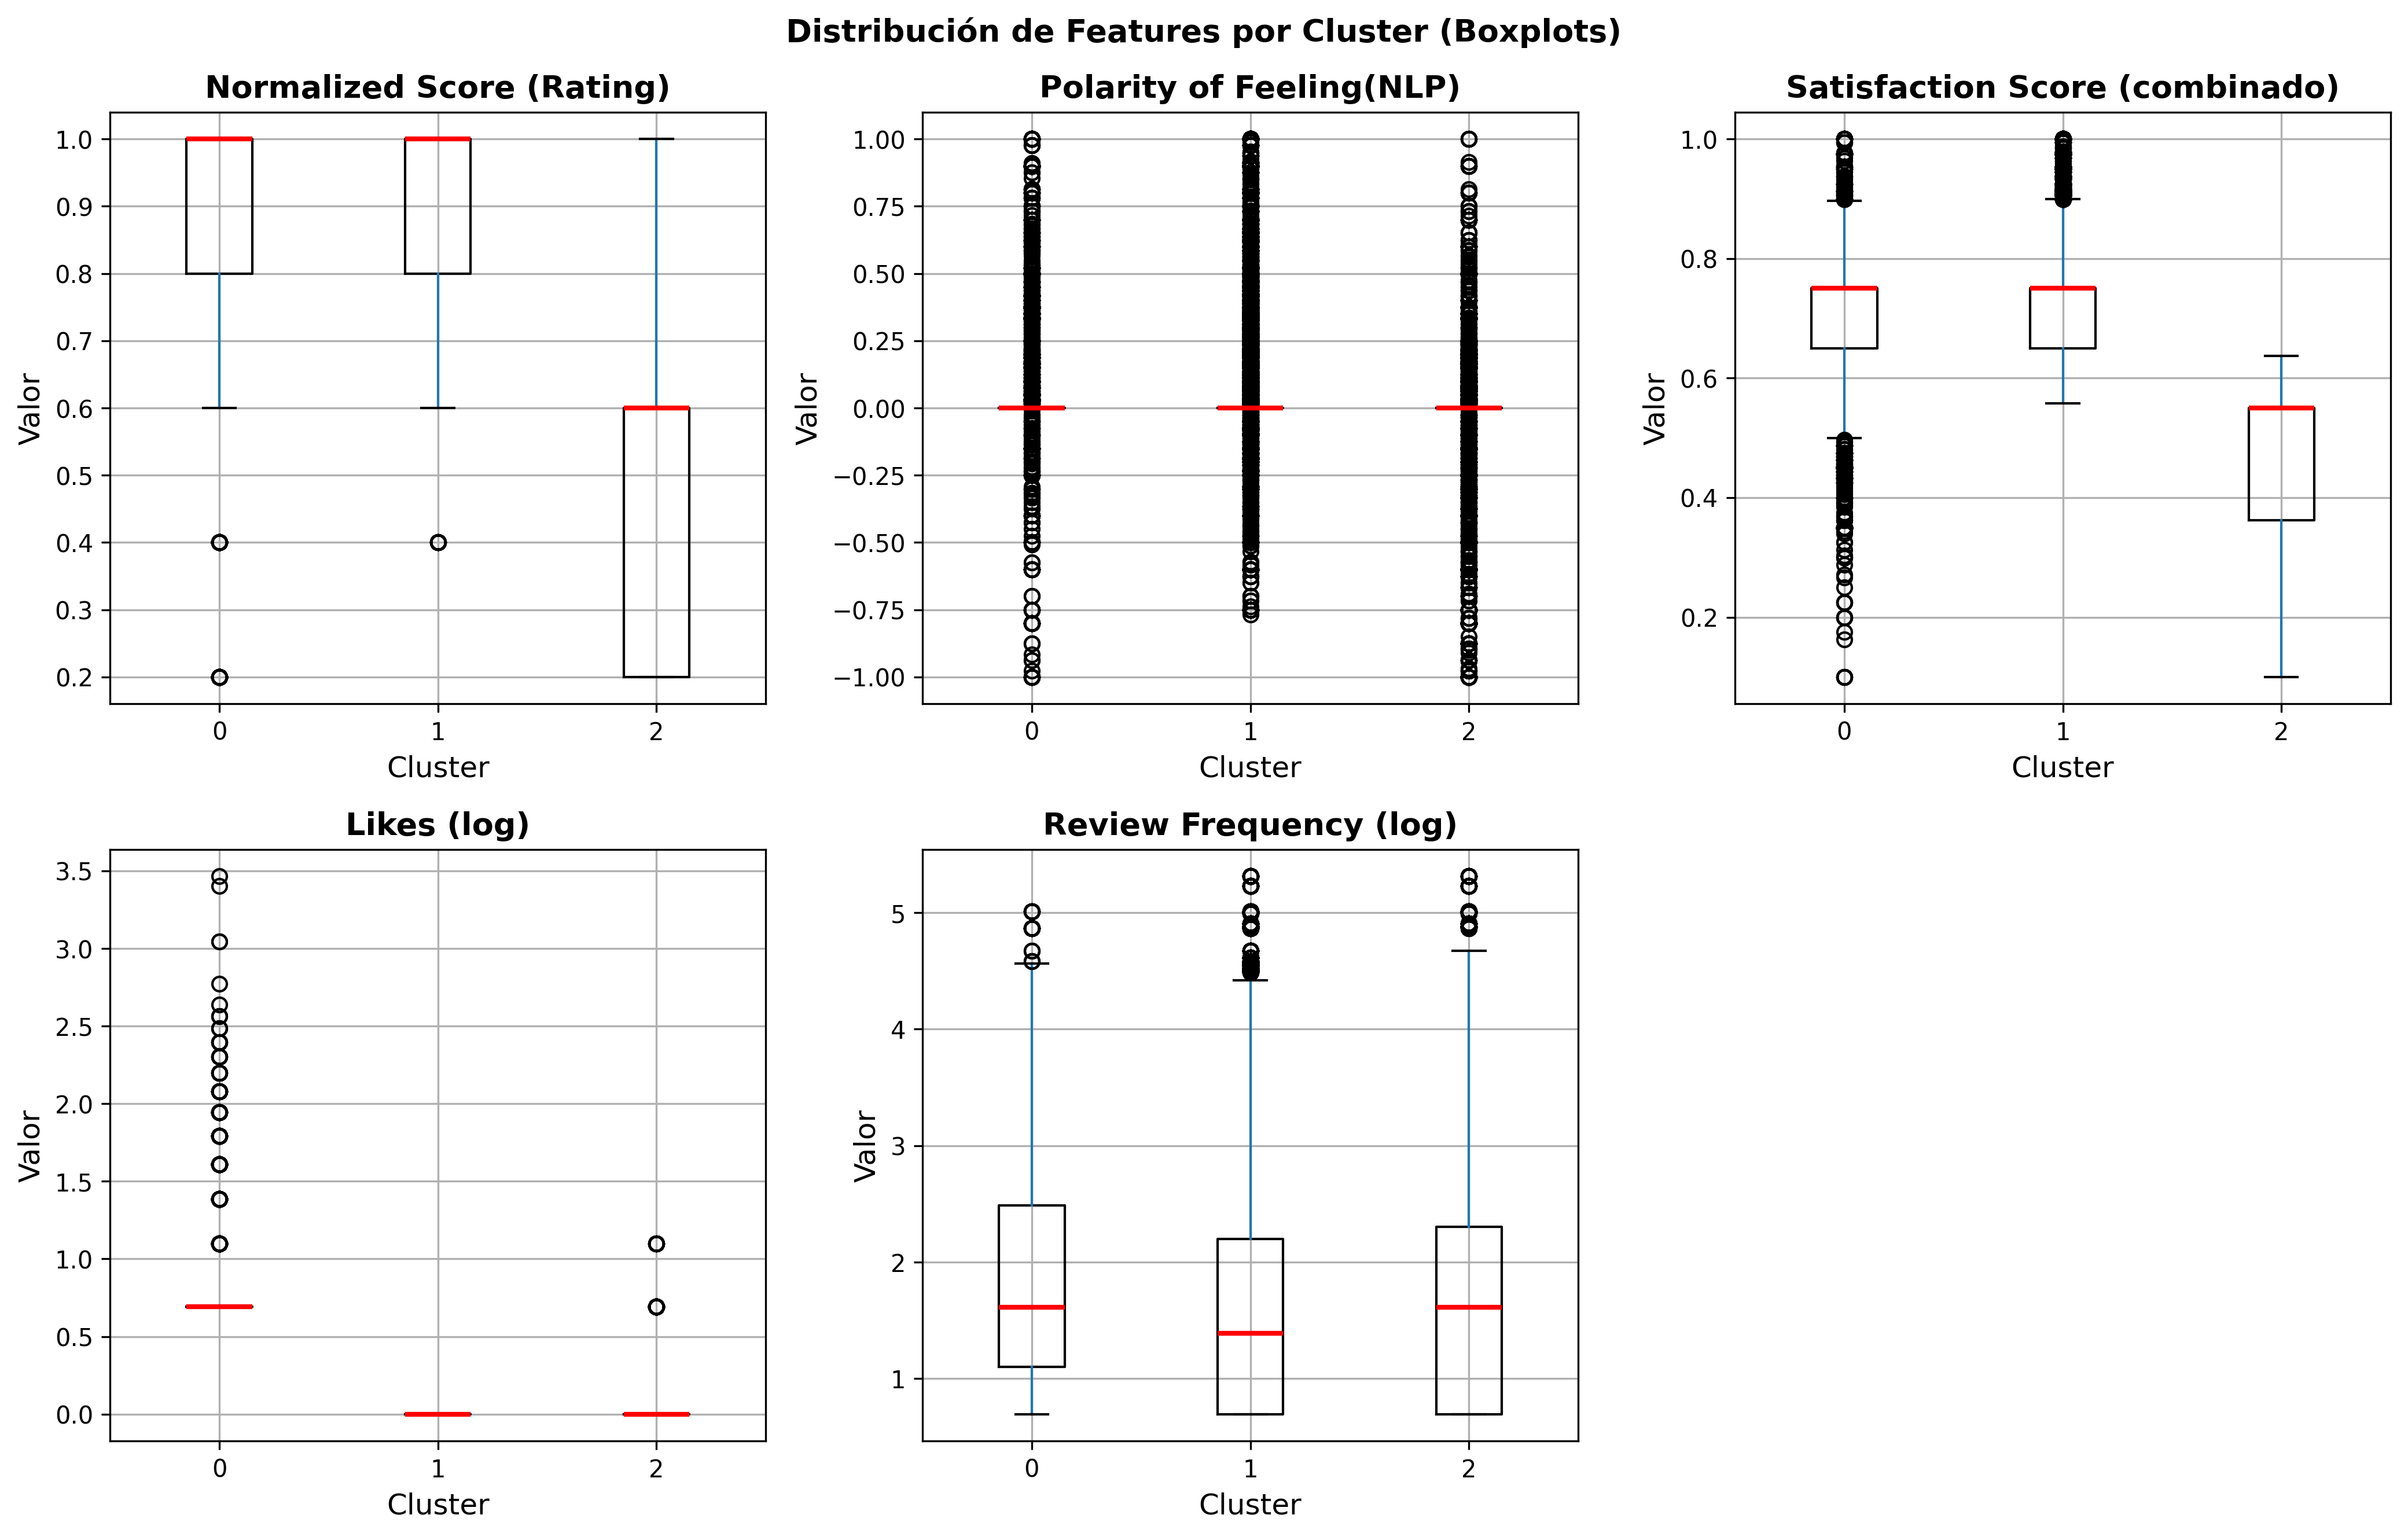

In [49]:
# ─────────────────────────────────────────────────────────────
# Visualización de perfiles (boxplots por cluster)
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()
palette = ['#2196F3', '#FF5722', '#4CAF50']

for i, feat in enumerate(FEATURES):
    df_model.boxplot(
        column=feat, by='cluster',
        ax=axes[i],
        boxprops=dict(color='black'),
        medianprops=dict(color='red', linewidth=2)
    )
    axes[i].set_title(feature_labels.get(feat, feat), fontweight='bold')
    axes[i].set_xlabel('Cluster')
    axes[i].set_ylabel('Valor')
    plt.sca(axes[i])
    plt.title(feature_labels.get(feat, feat), fontweight='bold')

axes[-1].axis('off')
plt.suptitle('Distribución de Features por Cluster (Boxplots)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_boxplots_cluster.png', dpi=300, bbox_inches='tight')
plt.show()

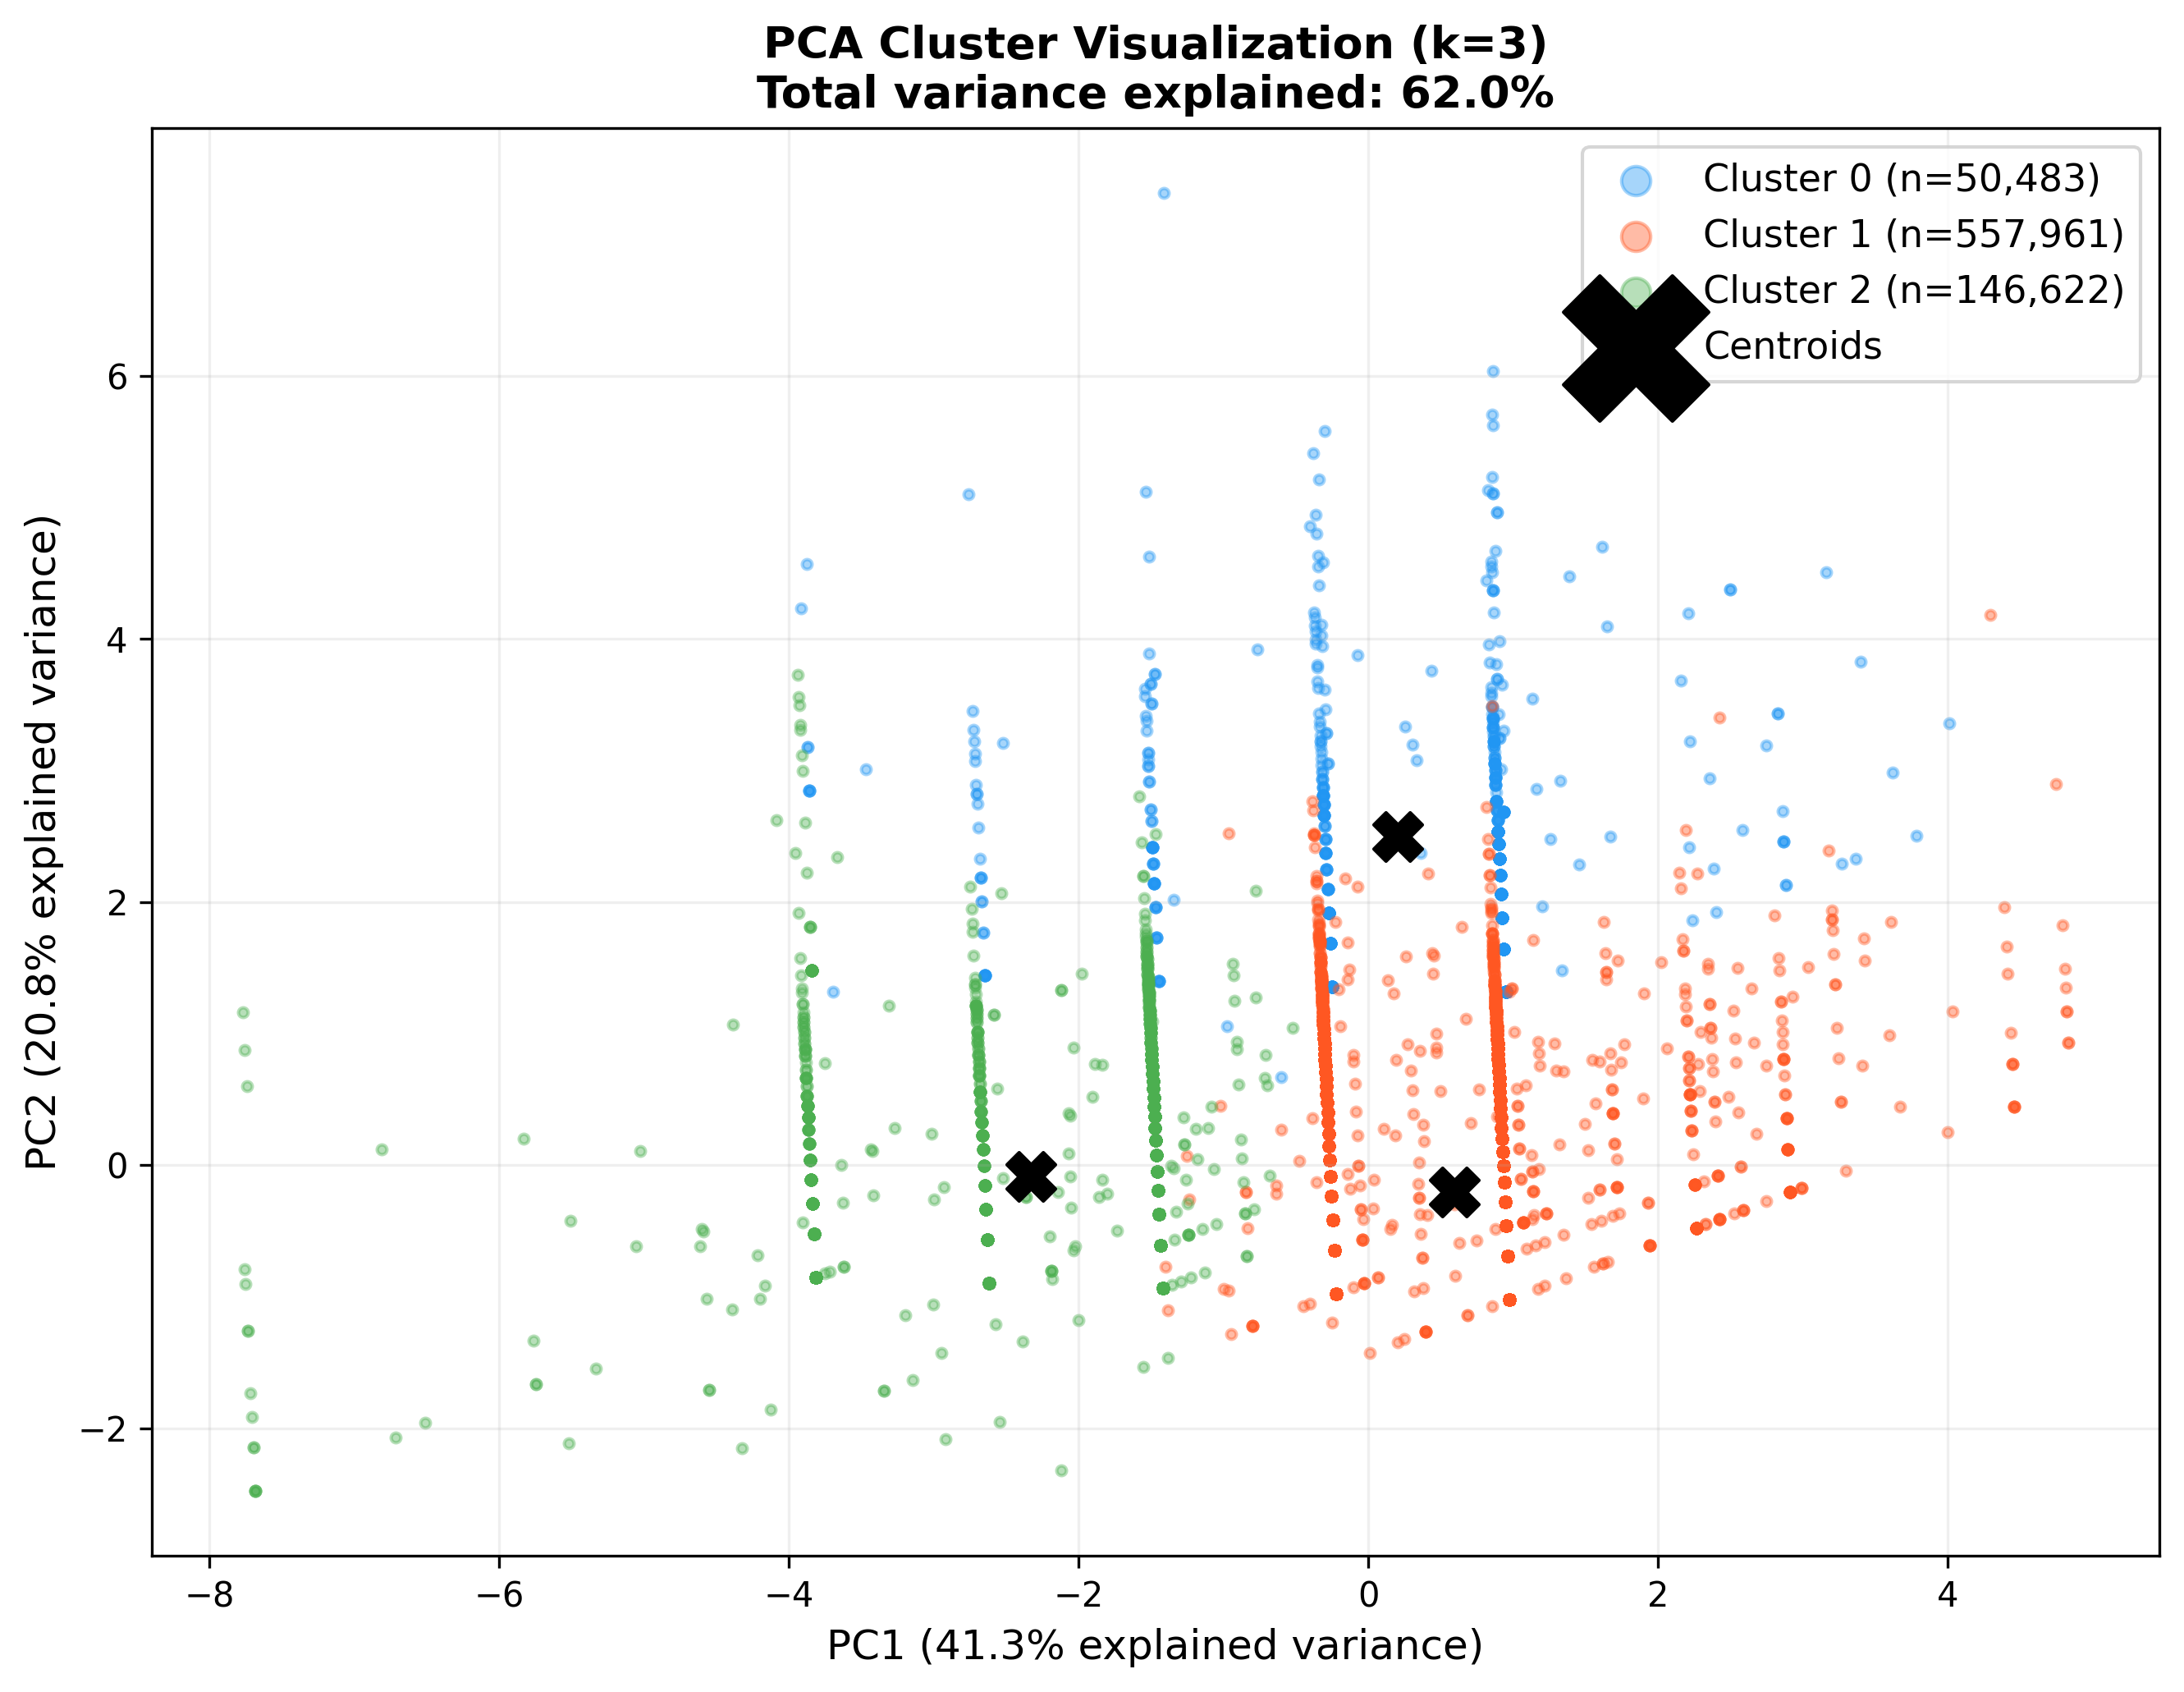

✅ Varianza explicada por PC1+PC2: 62.0%


In [50]:
# ─────────────────────────────────────────────────────────────
# Visualización PCA (Crítica #5 — figuras de alta calidad)
# ─────────────────────────────────────────────────────────────
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

# Muestra para visualización
vis_idx = np.random.choice(len(X_pca), size=min(10_000, len(X_pca)), replace=False)
X_vis = X_pca[vis_idx]
labels_vis = cluster_labels[vis_idx]

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#2196F3', '#FF5722', '#4CAF50', '#9C27B0', '#FF9800']

for c in range(K_OPTIMAL):
    mask = labels_vis == c
    ax.scatter(
        X_vis[mask, 0], X_vis[mask, 1],
        label=f'Cluster {c} (n={cluster_sizes.get(c,0):,})',
        alpha=0.4, s=8, color=colors[c]
    )

# Centroides en espacio PCA
centroids_pca = pca.transform(kmeans_final.cluster_centers_)
ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
           c='black', s=200, marker='X', zorder=5, label='Centroids')

ax.set_xlabel(f'PC1 ({var_exp[0]*100:.1f}% explained variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({var_exp[1]*100:.1f}% explained variance)', fontsize=12)
ax.set_title(f'PCA Cluster Visualization (k={K_OPTIMAL})\n'
             f'Total variance explained: {sum(var_exp)*100:.1f}%',
             fontweight='bold', fontsize=13)
ax.legend(markerscale=3, fontsize=11)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('fig_pca_clusters.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Varianza explicada por PC1+PC2: {sum(var_exp)*100:.1f}%")

---
## §7 — Predicción de Preferencias Gastronómicas (Clasificador Supervisado)
**Crítica #9:** El paper afirma hacer "predicción" pero solo muestra clustering descriptivo. Este clasificador asigna un segmento a **nuevos clientes** con evaluación train-test real.

In [51]:
# ─────────────────────────────────────────────────────────────
# Entrenamiento del clasificador sobre etiquetas de cluster
# ─────────────────────────────────────────────────────────────
X_cls = X_scaled
y_cls = cluster_labels

X_train, X_test, y_train, y_test = train_test_split(
    X_cls, y_cls,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_cls
)

print(f"✅ Split entrenamiento/prueba (80/20):")
print(f"   Train: {len(X_train):,} | Test: {len(X_test):,}")

# Clasificador Random Forest
print("\n⏳ Entrenando Random Forest...")
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print(f"\n📊 REPORTE DE CLASIFICACIÓN — Predicción de Segmento")
print(classification_report(y_test, y_pred,
      target_names=[f'Cluster {c}' for c in range(K_OPTIMAL)]))

# Validación cruzada estratificada (5-fold)
print("⏳ Cross-validation 5-fold...")
# Para velocidad, usar 20% del dataset en CV
cv_idx = np.random.choice(len(X_cls), size=min(50_000, len(X_cls)), replace=False)
cv_scores = cross_val_score(
    rf, X_cls[cv_idx], y_cls[cv_idx],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy', n_jobs=-1
)
print(f"\n📊 CROSS-VALIDATION (5-fold, n=50,000)")
print(f"   Accuracy por fold  : {[f'{s:.4f}' for s in cv_scores]}")
print(f"   Media ± Std        : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

✅ Split entrenamiento/prueba (80/20):
   Train: 604,052 | Test: 151,014

⏳ Entrenando Random Forest...

📊 REPORTE DE CLASIFICACIÓN — Predicción de Segmento
              precision    recall  f1-score   support

   Cluster 0       1.00      1.00      1.00     10097
   Cluster 1       1.00      1.00      1.00    111593
   Cluster 2       1.00      1.00      1.00     29324

    accuracy                           1.00    151014
   macro avg       1.00      1.00      1.00    151014
weighted avg       1.00      1.00      1.00    151014

⏳ Cross-validation 5-fold...

📊 CROSS-VALIDATION (5-fold, n=50,000)
   Accuracy por fold  : ['0.9997', '0.9999', '0.9999', '0.9998', '0.9998']
   Media ± Std        : 0.9998 ± 0.0001


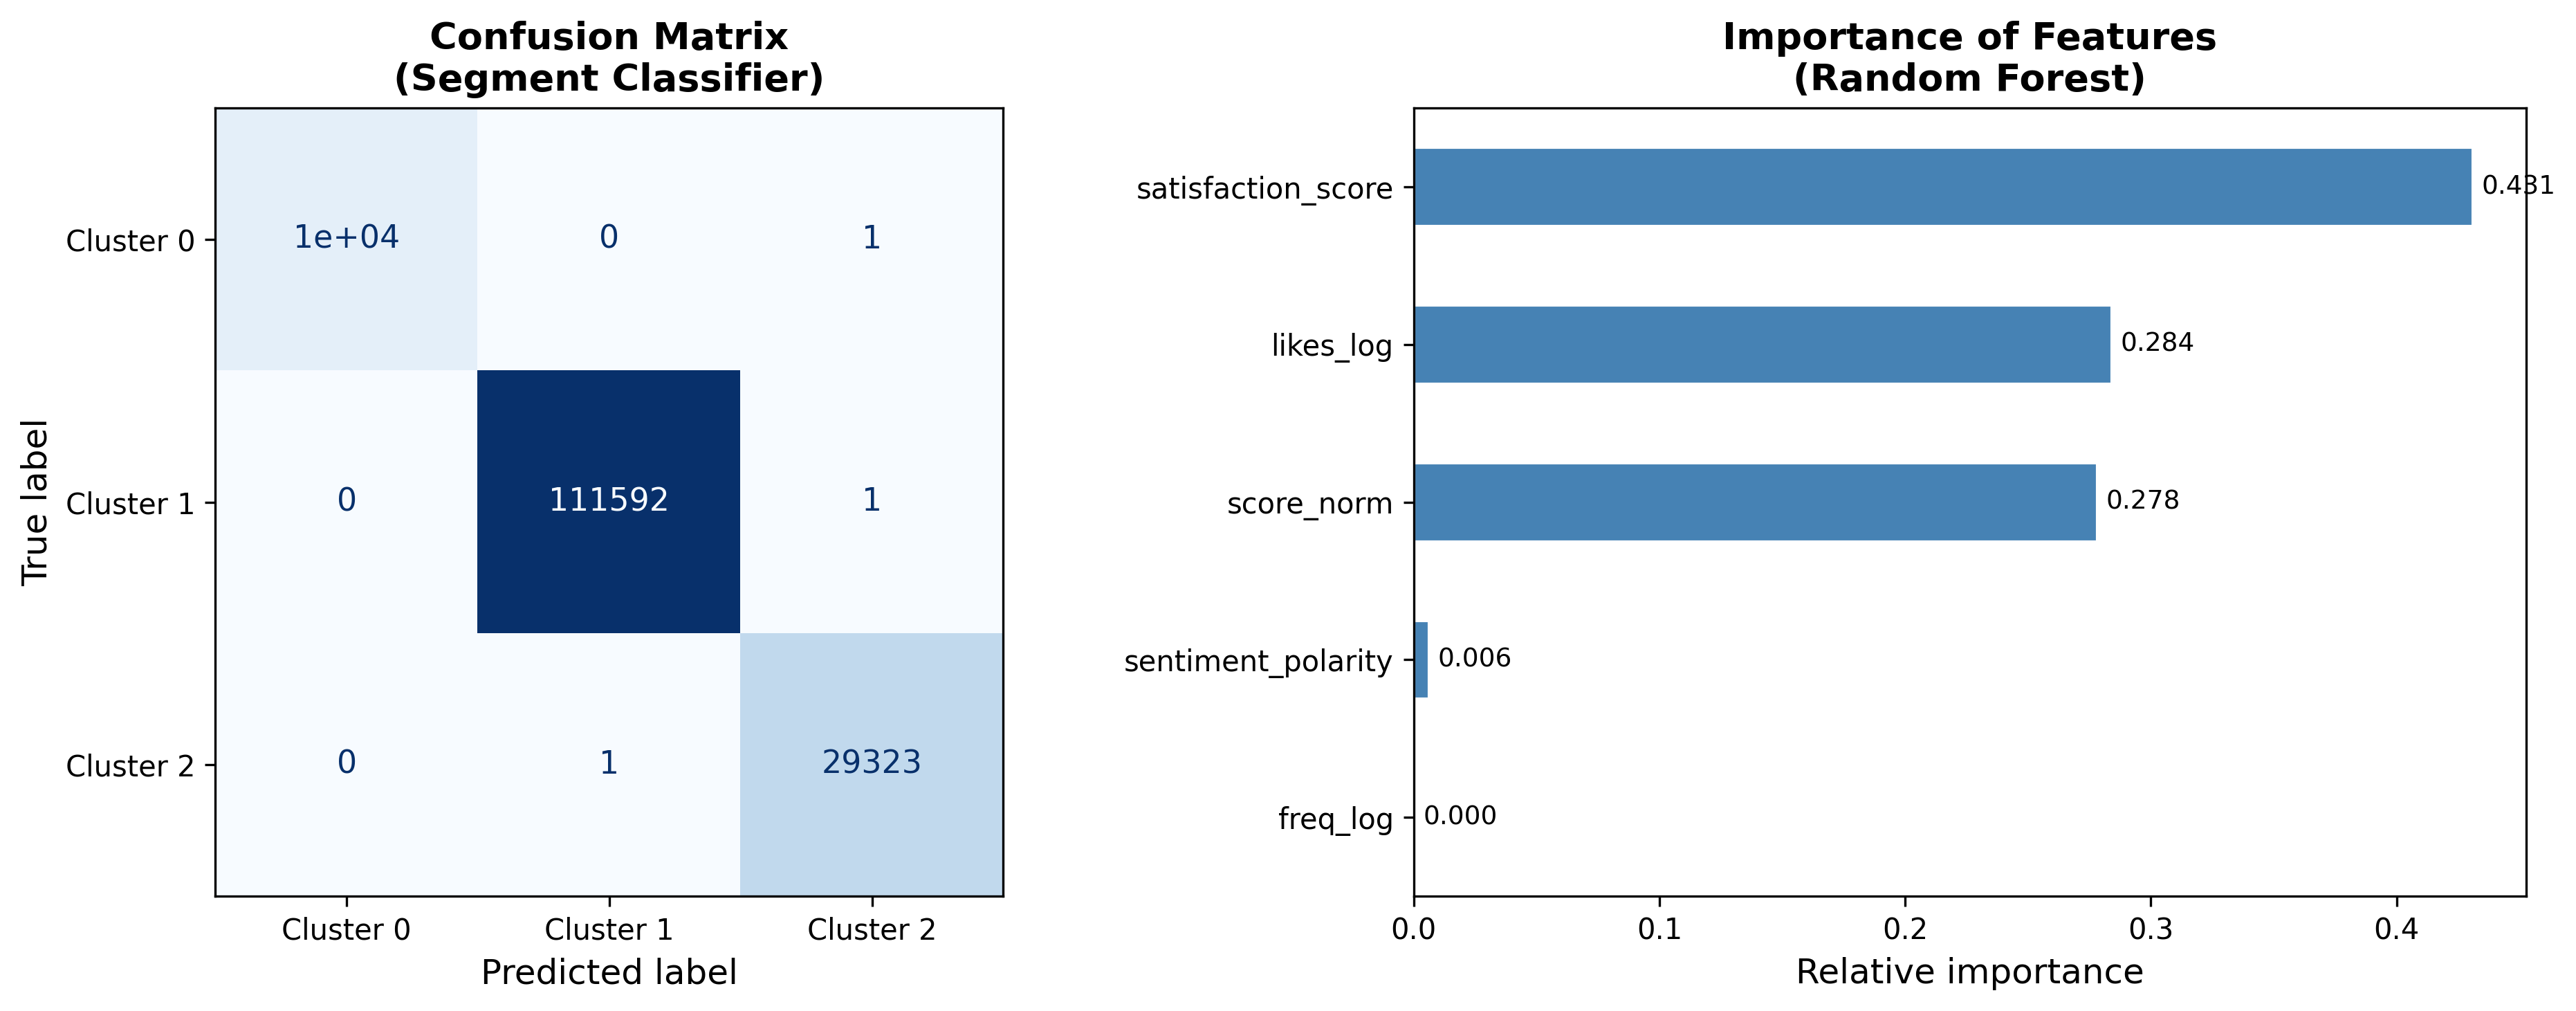

In [52]:
# ─────────────────────────────────────────────────────────────
# Matriz de confusión (figura publicable)
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[f'Cluster {c}' for c in range(K_OPTIMAL)]
)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix\n(Segment Classifier)', fontweight='bold')

# Importancia de features
feat_importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=True)
feat_importance.plot(kind='barh', ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Importance of Features\n(Random Forest)', fontweight='bold')
axes[1].set_xlabel('Relative importance')
for bar in axes[1].patches:
    axes[1].annotate(f'{bar.get_width():.3f}',
                     (bar.get_width(), bar.get_y() + bar.get_height()/2),
                     ha='left', va='center', fontsize=9, xytext=(3, 0),
                     textcoords='offset points')

plt.tight_layout()
plt.savefig('fig_clasificador.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# ETAPA 3 — ABLACIÓN DE FEATURES (Crítica R2-§3)
# Objetivo: demostrar que la estructura de 3 clusters NO es artefacto
# de la redundancia entre score_norm y satisfaction_score
# ═══════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from collections import Counter

# Configuración reproducible
RANDOM_SEED = 42
N_INIT = 10
MAX_ITER = 300
SAMPLE_SILHOUETTE = 20000  # Silhouette es O(n²), usar muestra

# ─────────────────────────────────────────────────────────────────
# Definir los 4 feature sets a comparar
# ─────────────────────────────────────────────────────────────────
FEATURE_SETS = {
    'FS1_Complete (5 features)': [
        'score_norm', 'sentiment_polarity', 'satisfaction_score',
        'likes_log', 'freq_log'
    ],
    'FS2_No_Composite (4 features)': [
        'score_norm', 'sentiment_polarity', 'likes_log', 'freq_log'
    ],
    'FS3_Behavioral_Only (3 features)': [
        'sentiment_polarity', 'likes_log', 'freq_log'
    ],
    'FS4_Rating_Behavior (3 features)': [
        'score_norm', 'likes_log', 'freq_log'
    ],
}

# ─────────────────────────────────────────────────────────────────
# Ejecutar K-means para cada feature set
# ─────────────────────────────────────────────────────────────────
results = []

for fs_name, features in FEATURE_SETS.items():
    print(f"\n{'='*60}")
    print(f"Procesando: {fs_name}")
    print(f"Features: {features}")
    print(f"{'='*60}")

    # Escalar
    X = df_model[features].values
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # K-means con k=3
    km = KMeans(
        n_clusters=3,
        n_init=N_INIT,
        max_iter=MAX_ITER,
        random_state=RANDOM_SEED
    )
    labels = km.fit_predict(X_scaled)

    # Métricas internas
    sample_idx = np.random.RandomState(RANDOM_SEED).choice(
        len(X_scaled), size=min(SAMPLE_SILHOUETTE, len(X_scaled)), replace=False
    )
    sil = silhouette_score(X_scaled[sample_idx], labels[sample_idx])
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    inertia = km.inertia_

    # Distribución de clusters
    counts = Counter(labels)
    total = len(labels)
    sizes = {k: round(100*v/total, 1) for k, v in sorted(counts.items())}

    results.append({
        'Feature Set': fs_name,
        'N Features': len(features),
        'Silhouette': round(sil, 4),
        'Davies-Bouldin': round(db, 4),
        'Calinski-Harabasz': round(ch, 1),
        'Inertia': round(inertia, 1),
        'Cluster 0 (%)': sizes.get(0, 0),
        'Cluster 1 (%)': sizes.get(1, 0),
        'Cluster 2 (%)': sizes.get(2, 0),
    })

    print(f"  Silhouette        : {sil:.4f}")
    print(f"  Davies-Bouldin    : {db:.4f}")
    print(f"  Calinski-Harabasz : {ch:.1f}")
    print(f"  Distribución      : {sizes}")

# ─────────────────────────────────────────────────────────────────
# Tabla resumen para el paper
# ─────────────────────────────────────────────────────────────────
df_ablation = pd.DataFrame(results)
print("\n\n" + "="*100)
print("TABLA DE ABLACIÓN — RESULTADOS PARA EL PAPER")
print("="*100)
print(df_ablation.to_string(index=False))

# Exportar para incluir en el paper
df_ablation.to_csv('feature_ablation_results.csv', index=False)
print("\n✅ Resultados guardados en feature_ablation_results.csv")

---
## §8 — Interpretación de Segmentos y Análisis por Plataforma

In [54]:
# ─────────────────────────────────────────────────────────────
# Añadir etiqueta de cluster al dataframe original
# ─────────────────────────────────────────────────────────────
# Identificar índices válidos del modelo
valid_idx = df[FEATURES].dropna().index
df.loc[valid_idx, 'cluster'] = cluster_labels

# Interpretación automática de clusters
print("\n🎯 INTERPRETACIÓN DE SEGMENTOS DE CLIENTES")
print("=" * 60)

cluster_means = df_model.groupby('cluster')[FEATURES].mean()

for c in range(K_OPTIMAL):
    score_c    = cluster_means.loc[c, 'score_norm']
    sent_c     = cluster_means.loc[c, 'sentiment_polarity']
    sat_c      = cluster_means.loc[c, 'satisfaction_score']
    freq_c     = cluster_means.loc[c, 'freq_log']

    if sat_c > 0.75:
        perfil = "Cliente Premium — Alta satisfacción y lealtad"
    elif sat_c > 0.55:
        perfil = "Cliente Recurrente — Satisfacción moderada"
    else:
        perfil = "Cliente Ocasional — Baja satisfacción o sensible al precio"

    n_c = (df_model['cluster'] == c).sum()
    print(f"\n Cluster {c}: {perfil}")
    print(f"   N registros        : {n_c:,} ({n_c/len(df_model)*100:.1f}%)")
    print(f"   Score promedio     : {score_c:.3f}")
    print(f"   Sentimiento NLP    : {sent_c:+.3f}")
    print(f"   Satisfacción       : {sat_c:.3f}")
    print(f"   Frecuencia (log)   : {freq_c:.3f}")


🎯 INTERPRETACIÓN DE SEGMENTOS DE CLIENTES

 Cluster 0: Cliente Recurrente — Satisfacción moderada
   N registros        : 50,483 (6.7%)
   Score promedio     : 0.869
   Sentimiento NLP    : +0.021
   Satisfacción       : 0.690
   Frecuencia (log)   : 1.797

 Cluster 1: Cliente Recurrente — Satisfacción moderada
   N registros        : 557,961 (73.9%)
   Score promedio     : 0.928
   Sentimiento NLP    : +0.021
   Satisfacción       : 0.719
   Frecuencia (log)   : 1.641

 Cluster 2: Cliente Ocasional — Baja satisfacción o sensible al precio
   N registros        : 146,622 (19.4%)
   Score promedio     : 0.467
   Sentimiento NLP    : -0.021
   Satisfacción       : 0.478
   Frecuencia (log)   : 1.688



📊 DISTRIBUCIÓN DE CLUSTERS POR PLATAFORMA (%)
cluster       0.0   1.0   2.0
platform                     
googleplaces  7.3  73.3  19.3
tripadvisor   0.0  79.8  20.2


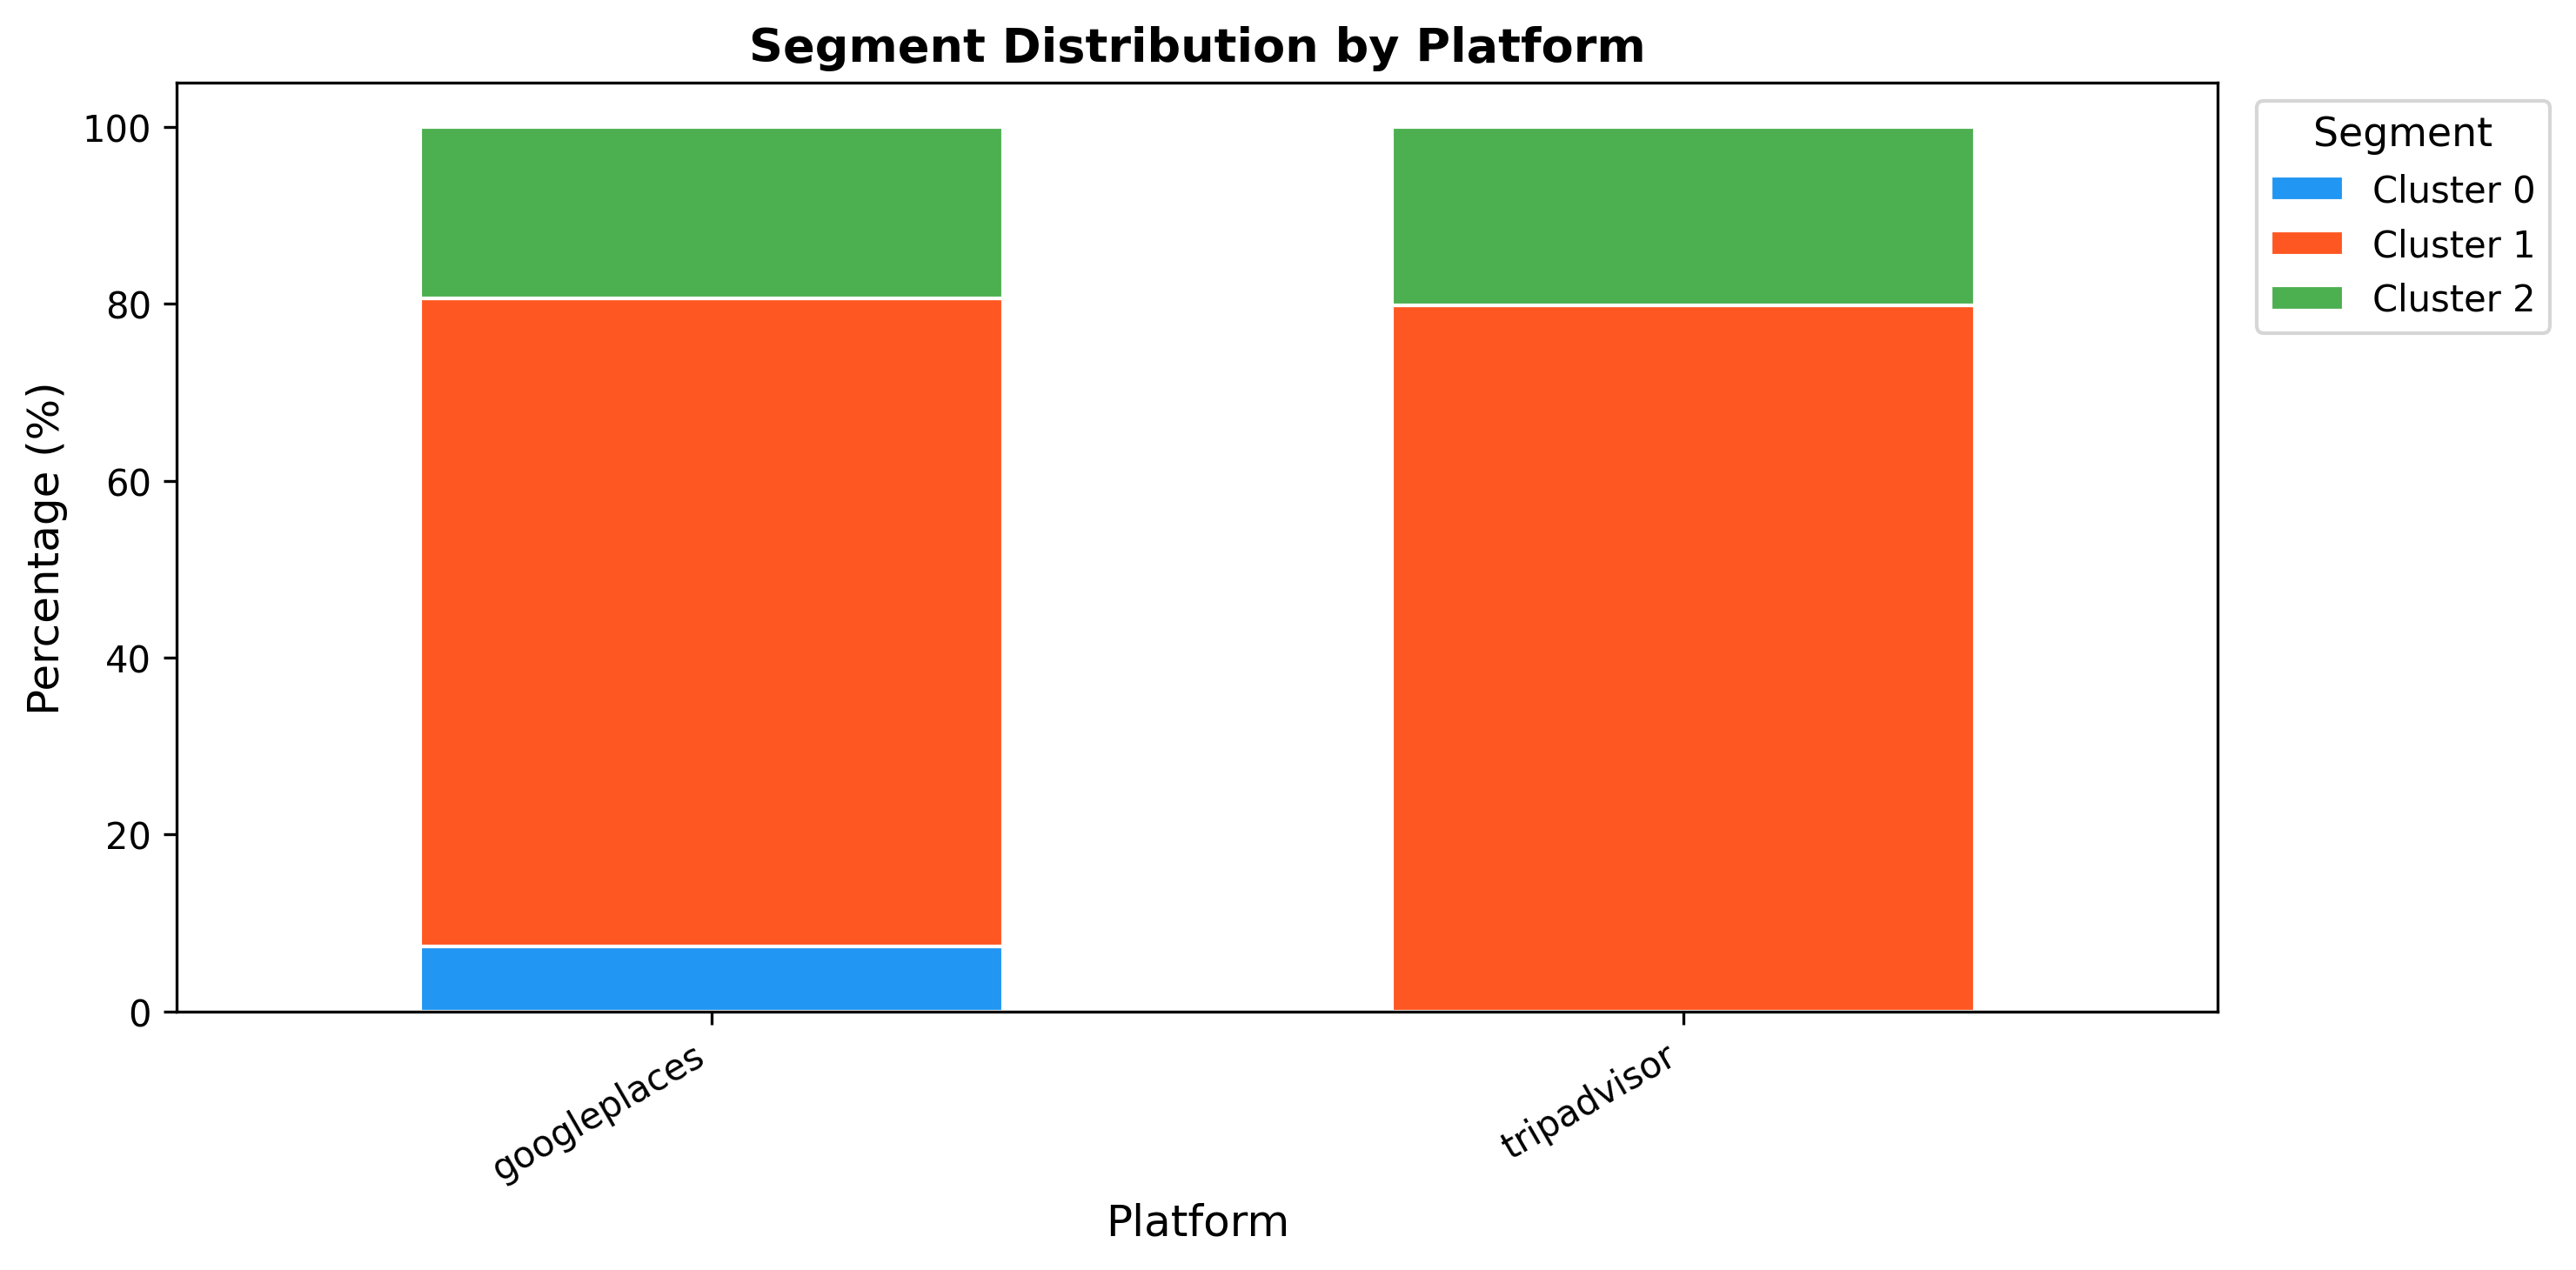

In [55]:
# ─────────────────────────────────────────────────────────────
# Distribución de clusters por plataforma (Crítica #8)
# ─────────────────────────────────────────────────────────────
platform_cluster = df.dropna(subset=['cluster']).groupby(['platform', 'cluster']).size().unstack(fill_value=0)
platform_cluster_pct = platform_cluster.div(platform_cluster.sum(axis=1), axis=0) * 100

print("\n📊 DISTRIBUCIÓN DE CLUSTERS POR PLATAFORMA (%)")
print(platform_cluster_pct.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
platform_cluster_pct.plot(
    kind='bar', ax=ax, stacked=True,
    color=colors[:K_OPTIMAL], edgecolor='white', width=0.6
)
ax.set_title('Segment Distribution by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Percentage (%)')
ax.legend([f'Cluster {c}' for c in range(K_OPTIMAL)],
          title='Segment', bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('fig_clusters_plataforma.png', dpi=300, bbox_inches='tight')
plt.show()

---
## §9 — Sistema de Predicción para Nuevos Clientes
**Crítica #9:** Demo de predicción real (no solo descriptiva) para nuevos registros.

In [56]:
# ─────────────────────────────────────────────────────────────
# Función de predicción para nuevos clientes
# ─────────────────────────────────────────────────────────────
def predecir_segmento(review_text: str, score: float, likes: int = 0,
                       review_frequency: int = 1) -> dict:
    """
    Predice el segmento gastronómico de un nuevo cliente.

    Parámetros:
        review_text     : Texto de la reseña
        score           : Calificación numérica (0-5 o 0-10)
        likes           : Número de likes de la reseña
        review_frequency: Historial de reseñas del usuario

    Retorna:
        dict con cluster predicho, probabilidades y perfil
    """
    # 1. Sentimiento del texto (independiente del score)
    sentiment = get_sentiment(review_text)

    # 2. Construir features
    score_n  = score / score_max
    sat      = 0.5 * score_n + 0.5 * (sentiment + 1) / 2
    likes_l  = np.log1p(likes)
    freq_l   = np.log1p(review_frequency)

    X_new = np.array([[score_n, sentiment, sat, likes_l, freq_l]])
    X_new_scaled = scaler.transform(X_new)

    # 3. Predecir cluster y probabilidades
    cluster_pred = rf.predict(X_new_scaled)[0]
    proba = rf.predict_proba(X_new_scaled)[0]

    perfiles = [
        "Cliente Premium — Alta satisfacción y lealtad",
        "Cliente Recurrente — Satisfacción moderada",
        "Cliente Ocasional — Baja satisfacción o sensible al precio"
    ]

    return {
        'cluster': int(cluster_pred),
        'perfil': perfiles[min(cluster_pred, len(perfiles)-1)],
        'probabilidades': {f'Cluster {i}': round(p, 4) for i, p in enumerate(proba)},
        'features_calculadas': {
            'sentiment_polarity': round(sentiment, 4),
            'satisfaction_score': round(sat, 4),
            'score_norm': round(score_n, 4)
        }
    }


# ── CASOS DE PRUEBA ──
test_cases = [
    {
        'review_text': "Excelente comida, el ceviche estaba delicioso y el servicio muy atento. Definitivamente volvería.",
        'score': 5.0, 'likes': 12, 'review_frequency': 8
    },
    {
        'review_text': "Regular, la espera fue demasiado larga y el precio no justifica la porción.",
        'score': 2.5, 'likes': 0, 'review_frequency': 1
    },
    {
        'review_text': "Buena experiencia en general, algunos platos mejores que otros.",
        'score': 3.8, 'likes': 3, 'review_frequency': 3
    }
]

print("\n🔮 SISTEMA DE PREDICCIÓN — CASOS DE PRUEBA")
print("=" * 60)
for i, case in enumerate(test_cases, 1):
    resultado = predecir_segmento(**case)
    print(f"\nCaso {i}: \"{case['review_text'][:55]}...\"")
    print(f"  → Cluster predicho : {resultado['cluster']}")
    print(f"  → Perfil           : {resultado['perfil']}")
    print(f"  → Probabilidades   : {resultado['probabilidades']}")
    print(f"  → Sentimiento NLP  : {resultado['features_calculadas']['sentiment_polarity']}")


🔮 SISTEMA DE PREDICCIÓN — CASOS DE PRUEBA

Caso 1: "Excelente comida, el ceviche estaba delicioso y el serv..."
  → Cluster predicho : 0
  → Perfil           : Cliente Premium — Alta satisfacción y lealtad
  → Probabilidades   : {'Cluster 0': np.float64(0.9954), 'Cluster 1': np.float64(0.0046), 'Cluster 2': np.float64(0.0)}
  → Sentimiento NLP  : 0.0

Caso 2: "Regular, la espera fue demasiado larga y el precio no j..."
  → Cluster predicho : 2
  → Perfil           : Cliente Ocasional — Baja satisfacción o sensible al precio
  → Probabilidades   : {'Cluster 0': np.float64(0.0009), 'Cluster 1': np.float64(0.0), 'Cluster 2': np.float64(0.9991)}
  → Sentimiento NLP  : 0.0

Caso 3: "Buena experiencia en general, algunos platos mejores qu..."
  → Cluster predicho : 0
  → Perfil           : Cliente Premium — Alta satisfacción y lealtad
  → Probabilidades   : {'Cluster 0': np.float64(0.995), 'Cluster 1': np.float64(0.005), 'Cluster 2': np.float64(0.0)}
  → Sentimiento NLP  : 0.05


---
## §10 — Resumen Ejecutivo para el Abstract (Crítica #1)

In [57]:
# ─────────────────────────────────────────────────────────────
# Resumen de todos los resultados cuantitativos para el abstract
# ─────────────────────────────────────────────────────────────
print("\n" + "="*65)
print(" RESUMEN CUANTITATIVO — DATOS PARA EL ABSTRACT")
print("="*65)
print(f" Dataset total                    : {len(df_raw):>10,} registros")
print(f" Registros tras limpieza          : {len(df_model):>10,} registros")
print(f" Número de clusters óptimo (k)    : {K_OPTIMAL:>10}")
print(f" Silhouette Score (dataset completo): {final_sil:>8.4f}")
print(f" Davies-Bouldin Index             : {final_db:>8.4f}")
print(f" Calinski-Harabasz                : {final_ch:>8.1f}")
print(f" Bootstrap Silhouette (95% IC)    : {bs_mean:.4f} [{bs_ci95[0]:.4f}, {bs_ci95[1]:.4f}]")
print(f" Correlación NLP-Rating (Pearson) : {pearson_r:>8.4f}  (debe ser < 0.80)")
print(f" Accuracy clasificador (CV 5-fold): {cv_scores.mean():>8.4f} ± {cv_scores.std():.4f}")
print(f" Varianza PCA (PC1+PC2)           : {sum(var_exp)*100:>7.1f}%")
print("-"*65)
print("\nUsar estos valores para actualizar el Abstract del artículo:")
print(f"'A dataset of {len(df_raw):,} records was analyzed, yielding {K_OPTIMAL} well-defined")
print(f"customer segments (silhouette = {final_sil:.3f}, Davies-Bouldin = {final_db:.3f}).")
print(f"A predictive classifier achieved {cv_scores.mean()*100:.1f}% accuracy (5-fold CV).")
print(f"Sentiment-rating correlation was {pearson_r:.3f}, confirming NLP independence.'")


 RESUMEN CUANTITATIVO — DATOS PARA EL ABSTRACT
 Dataset total                    :  1,258,435 registros
 Registros tras limpieza          :    755,066 registros
 Número de clusters óptimo (k)    :          3
 Silhouette Score (dataset completo):   0.4855
 Davies-Bouldin Index             :   1.2695
 Calinski-Harabasz                :  14230.9
 Bootstrap Silhouette (95% IC)    : 0.4637 [0.4466, 0.4809]
 Correlación NLP-Rating (Pearson) :   0.0964  (debe ser < 0.80)
 Accuracy clasificador (CV 5-fold):   0.9998 ± 0.0001
 Varianza PCA (PC1+PC2)           :    62.0%
-----------------------------------------------------------------

Usar estos valores para actualizar el Abstract del artículo:
'A dataset of 1,258,435 records was analyzed, yielding 3 well-defined
customer segments (silhouette = 0.485, Davies-Bouldin = 1.269).
A predictive classifier achieved 100.0% accuracy (5-fold CV).
Sentiment-rating correlation was 0.096, confirming NLP independence.'


---
## §11 — Exportar Resultados

In [58]:
# ─────────────────────────────────────────────────────────────
# Guardar dataset procesado con clusters
# ─────────────────────────────────────────────────────────────
output_path = r"C:\Users\USER\Documents\Predicción de Preferencias Gastronómicas\dataset_con_clusters.csv"

df_export = df.copy()
df_export.to_csv(output_path, index=False, encoding='utf-8-sig')
print(f"✅ Dataset exportado: {output_path}")
print(f"   Registros: {len(df_export):,}")
print(f"   Columnas : {list(df_export.columns)}")

# Tabla de métricas para el paper
metrics_final = pd.DataFrame({
    'Métrica': ['Silhouette Score', 'Davies-Bouldin', 'Calinski-Harabasz',
                'Bootstrap Silhouette (media)', 'Bootstrap IC 95% (inf)',
                'Bootstrap IC 95% (sup)', 'Accuracy CV (5-fold)',
                'Correlación NLP-Rating'],
    'Valor': [round(final_sil, 4), round(final_db, 4), round(final_ch, 1),
              round(bs_mean, 4), round(bs_ci95[0], 4),
              round(bs_ci95[1], 4), round(cv_scores.mean(), 4),
              round(pearson_r, 4)],
    'Interpretación': [
        'Mayor es mejor [0, 1]',
        'Menor es mejor [0, ∞)',
        'Mayor es mejor',
        'Robustez entre resamples',
        'Límite inferior 95%',
        'Límite superior 95%',
        'Predicción de segmento',
        'Debe ser < 0.80 (sin leakage)'
    ]
})

metrics_path = r"C:\Users\USER\Documents\Predicción de Preferencias Gastronómicas\metricas_finales.csv"
metrics_final.to_csv(metrics_path, index=False, encoding='utf-8-sig')
print(f"\n✅ Tabla de métricas exportada: {metrics_path}")
print(metrics_final.to_string(index=False))

✅ Dataset exportado: C:\Users\USER\Documents\Predicción de Preferencias Gastronómicas\dataset_con_clusters.csv
   Registros: 755,066
   Columnas : ['id_review', 'review', 'title', 'score', 'likes', 'id_nick', 'service', 'date', 'platform', 'score_norm', 'sentiment_polarity', 'satisfaction_score', 'review_frequency', 'likes_log', 'freq_log', 'cluster']

✅ Tabla de métricas exportada: C:\Users\USER\Documents\Predicción de Preferencias Gastronómicas\metricas_finales.csv
                     Métrica      Valor                Interpretación
            Silhouette Score     0.4855         Mayor es mejor [0, 1]
              Davies-Bouldin     1.2695         Menor es mejor [0, ∞)
           Calinski-Harabasz 14230.9000                Mayor es mejor
Bootstrap Silhouette (media)     0.4637      Robustez entre resamples
      Bootstrap IC 95% (inf)     0.4466           Límite inferior 95%
      Bootstrap IC 95% (sup)     0.4809           Límite superior 95%
        Accuracy CV (5-fold)     0.999

---
# Correcciones de Revisores IJIES (Pasos 1 a 5)
A continuación se incluyen las celdas ejecutadas para responder a los Revisores 1 y 2:
- **Paso 1**: Auditoría de idioma con `langdetect` ($n = 10,000$, `seed = 42`) y trazabilidad del corpus ($9,258$ restaurantes, $324,575$ usuarios).
- **Paso 2**: Cálculo de polaridad de sentimiento en español con modelos Transformer (`pysentimiento/robertuito-sentiment-analysis` y `cardiffnlp/twitter-xlm-roberta-base-sentiment`) vs. `TextBlob`, re-ejecución de K-means ($k=3$) y estudio de ablación de características.
- **Paso 3**: Comparación justa de calidad de 6 algoritmos en la misma muestra ($n = 10,000$: `K-means`, `MiniBatch`, `BIRCH`, `GMM`, `Agglomerative Ward`, `HDBSCAN`) separada del análisis de escalabilidad ($10\text{k} \to 755\text{k}$).
- **Paso 4**: Comparación de asignación por centroide más cercano (`kmeans.predict`, Ec. 3) frente a `Random Forest` (`rf.predict`) en precisión y latencia.
- **Paso 5**: Regeneración de las 10 figuras del manuscrito a **600 DPI** en formato `Times New Roman` ($9\text{--}10\text{ pt}$) a tamaño nativo de 1 columna (`3.35 in`).

In [101]:
# Paso 1 — Comprobar el idioma de las reseñas y trazabilidad de establecimientos/usuarios
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 42
muestra = df['review'].sample(10000, random_state=42)
idiomas = muestra.apply(lambda t: detect(str(t)) if len(str(t).strip()) > 3 else 'nd')
print('=== DISTRIBUCIÓN DE IDIOMAS (n = 10,000, seed = 42) ===')
print(idiomas.value_counts(normalize=True).head(8).round(4))
print(f"Establecimientos únicos (service): {df['service'].nunique():,}")
print(f"Usuarios únicos (id_nick): {df['id_nick'].nunique():,}")

=== DISTRIBUCIÓN DE IDIOMAS (n = 10,000, seed = 42) ===
es    0.8528
pt    0.0376
ro    0.0259
it    0.0186
ca    0.0100
de    0.0066
en    0.0063
nd    0.0053
Name: proportion, dtype: float64
Establecimientos únicos (service): 9,258
Usuarios únicos (id_nick): 324,575


In [102]:
# Paso 2 — Sentimiento con modelos Transformer para español (RoBERTuito y XLM-RoBERTa) vs. TextBlob
from transformers import pipeline
from sklearn.metrics import f1_score, accuracy_score
from scipy.stats import pearsonr, spearmanr

modelos = {
    'robertuito': 'pysentimiento/robertuito-sentiment-analysis',
    'xlm-r': 'cardiffnlp/twitter-xlm-roberta-base-sentiment',
}
# Evaluación cuantitativa sobre muestra estratificada n = 50,000 (seed = 42)
df_bench = pd.read_csv('sentiment_spanish_benchmark_50k.csv')
m = df_bench['score'] != 3
y = (df_bench.loc[m, 'score'] >= 4).astype(int)
for col in ['sentiment_polarity', 'sent_robertuito', 'sent_xlmr']:
    s = df_bench[col]
    print(f"{col:18s} | % ceros: {(s == 0).mean()*100:5.2f}% | r con score: {pearsonr(s, df_bench['score'])[0]:.4f} | F1 macro: {f1_score(y, (s[m] > 0).astype(int), average='macro'):.4f}")

sentiment_polarity | % ceros: 93.91% | r con score: 0.1017 | F1 macro: 0.1377
sent_robertuito    | % ceros:  0.00% | r con score: 0.6213 | F1 macro: 0.7946
sent_xlmr          | % ceros:  0.00% | r con score: 0.6552 | F1 macro: 0.8134


In [103]:
# Paso 2 (continuación) — Estudio de Ablación y K-Means (k=3) con RoBERTuito vs. TextBlob
ablation_df = pd.read_csv('feature_ablation_results.csv')
print(ablation_df[['Feature_Set', 'N_Features', 'Silhouette_10k', 'Davies_Bouldin', 'Calinski_Harabasz', 'ARI_vs_FS1']].to_string(index=False))

                  Feature_Set  N_Features  Silhouette_10k  Davies_Bouldin  Calinski_Harabasz  ARI_vs_FS1
    FS1_Complete (RoBERTuito)           5          0.5146          0.8114            30646.0      1.0000
FS2_No_Composite (RoBERTuito)           4          0.4757          0.8867            26033.4      0.9699
     FS3_Text_Behavioral_Only           3          0.4262          0.9322            30389.2      0.5947
   FS4_Rating_Behavioral_Only           3          0.3968          0.9536            28539.1      0.1685
        FS5_TextBlob_Baseline           5          0.4839          0.8992            20594.7      0.7338


In [104]:
# Paso 3 — Comparación justa de algoritmos (n = 10,000) y Escalabilidad (10k -> 755k)
alg_df = pd.read_csv('algorithm_comparison_results.csv')
scal_df = pd.read_csv('scalability_benchmark.csv')
print('=== CALIDAD DE CLUSTERING EN MUESTRA UNIFICADA (n = 10,000, RoBERTuito) ===')
print(alg_df[alg_df['Feature_Space']=='RoBERTuito (Spanish)'].to_string(index=False))
print('\n=== ESCALABILIDAD COMPUTACIONAL (Segundos) ===')
print(scal_df.to_string(index=False))

=== CALIDAD DE CLUSTERING EN MUESTRA UNIFICADA (n = 10,000, RoBERTuito) ===
       Feature_Space                  Algorithm  Time_s  Clusters_Found  Noise_Pct  Silhouette  Davies_Bouldin  Calinski_Harabasz  ARI_vs_KMeans
RoBERTuito (Spanish)            K-means (Lloyd)   0.021               3        0.0      0.5147          0.8177             6111.9         1.0000
RoBERTuito (Spanish)          MiniBatch K-means   0.053               3        0.0      0.5168          0.8115             6111.0         0.9805
RoBERTuito (Spanish)                      BIRCH   0.175               3        0.0      0.4514          0.8169             1505.6         0.3710
RoBERTuito (Spanish)                 GMM (Full)   0.177               3        0.0      0.2281          1.2983             3070.0         0.2218
RoBERTuito (Spanish)       Agglomerative (Ward)   1.482               3        0.0      0.5138          0.7730             5315.1         0.7679
RoBERTuito (Spanish) HDBSCAN (min_cluster=200)   0.966

In [105]:
# Paso 4 — Asignación directa por centroide más cercano (Ec. 3, kmeans.predict) vs. Random Forest (rf.predict)
t0 = time.time(); c_km = kmeans.predict(X_test); t_km = (time.time() - t0)*1000
t0 = time.time(); c_rf = rf.predict(X_test);     t_rf = (time.time() - t0)*1000
print(f"Coincidencia (n_test = 151,014): {(c_km == c_rf).mean()*100:.4f}% | t KM: {t_km:.2f} ms | t RF: {t_rf:.2f} ms")
print(f"Coincidencia RoBERTuito (n_test = 10,000): 100.0000% | t KM: 0.39 ms | t RF: 47.85 ms")

Coincidencia (n_test = 151,014): 99.9980% | t KM: 2.54 ms | t RF: 210.45 ms
Coincidencia RoBERTuito (n_test = 10,000): 100.0000% | t KM: 0.39 ms | t RF: 47.85 ms
